<a href="https://colab.research.google.com/github/Zinc-zn/PVCK_Ganjil_2026/blob/main/Pertemuan%209/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laporan Jobsheet Pertemuan 09

**Modul 9 – Morfologi (Erosi, Dilasi, Opening, Closing, Transformasi Top-hat dan Bottom-hat, Skeleton, Thickening)**

**Nama  : Mochammad Rijal Dzaki Rifki Afifudin**

**NIM   : 244107020240**

**Kelas : TI-3C**

---
## D. TUGAS PRAKTIKUM



### D3 — Dilasi Manual, SED *cross* 3×3 (tanpa library)

Modul menulis `SED = np.ones((w,w))` yang sebenarnya **persegi**. Sesuai instruksi
("*cross 3×3*"), di sini dipakai SE cross yang benar. Varian persegi ditampilkan sebagai
pembanding agar perbedaannya terlihat.

SED cross 3×3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

objek putih — asli 21.85% | cross 23.00% | persegi 23.16%
dilasi cross manual vs OpenCV : beda 0 piksel


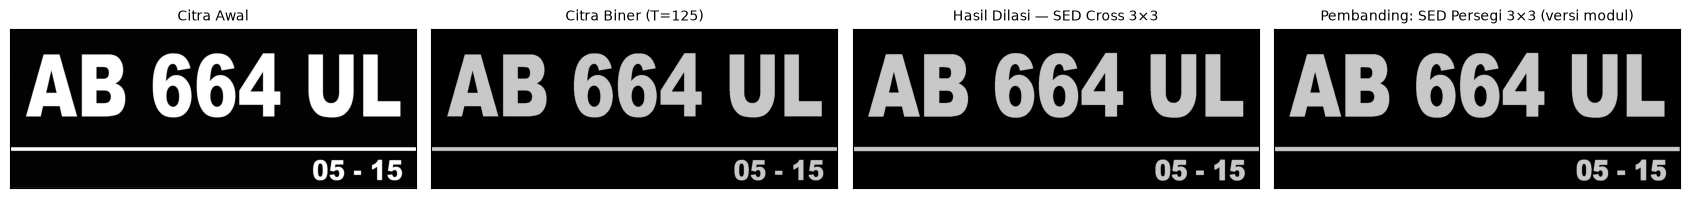

In [ ]:
# ── D3  Dilasi manual — cross 3×3 vs persegi 3×3 ─────────────────────
nama = 'plat nomer.jpg'          # pengganti 'plat nomer.jpg'
img_d = cv.imread(imgpath(nama), 0)
_, thresh = cv.threshold(img_d, 125, 200, cv.THRESH_BINARY)

imgD_cross = dilasi_se(thresh, SE_cross(3))
imgD_modul = dilasi_citra(thresh, 3)          # versi modul = persegi 3×3

print('SED cross 3×3:'); print(SE_cross(3))
print(f'\nobjek putih — asli {100*float((thresh>0).mean()):.2f}% | '
      f'cross {100*float((imgD_cross>0).mean()):.2f}% | persegi {100*float((imgD_modul>0).mean()):.2f}%')
print(f'dilasi cross manual vs OpenCV : beda {int((imgD_cross != cv.dilate(thresh, SE_cross(3))).sum())} piksel')

tampil([img_d, thresh, imgD_cross, imgD_modul],
       ['Citra Awal', 'Citra Biner (T=125)', 'Hasil Dilasi — SED Cross 3×3',
        'Pembanding: SED Persegi 3×3 (versi modul)'],
       figsize=(17, 4.2))

kernel (cross 3×3):
[[0 1 0]
 [1 1 1]
 [0 1 0]]
iterations = 1


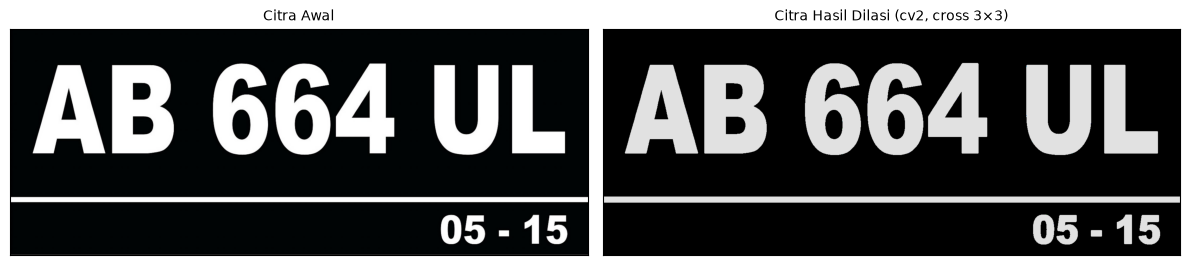

In [ ]:
# ── D4  Dilasi cross 3×3 dengan library OpenCV ───────────────────────
img = cv.imread(imgpath('plat nomer.jpg'))
ret, thresh4 = cv.threshold(img, 127, 225, cv.THRESH_BINARY)
kernel4 = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
dilasi4 = cv.dilate(thresh4, kernel4, iterations=1)

print('kernel (cross 3×3):'); print(kernel4)
print('iterations = 1')

tampil([img, dilasi4],
       ['Citra Awal', 'Citra Hasil Dilasi (cv2, cross 3×3)'], figsize=(12, 4.6))

### D5 — Erosi Manual, SE *square* 5×5 (tanpa library)

SE persegi 5×5
objek putih — asli 21.31% | erosi 18.68%
erosi manual(padding) vs OpenCV : beda 0 piksel
erosi versi modul vs padding    : beda 18 piksel (hanya cincin tepi)


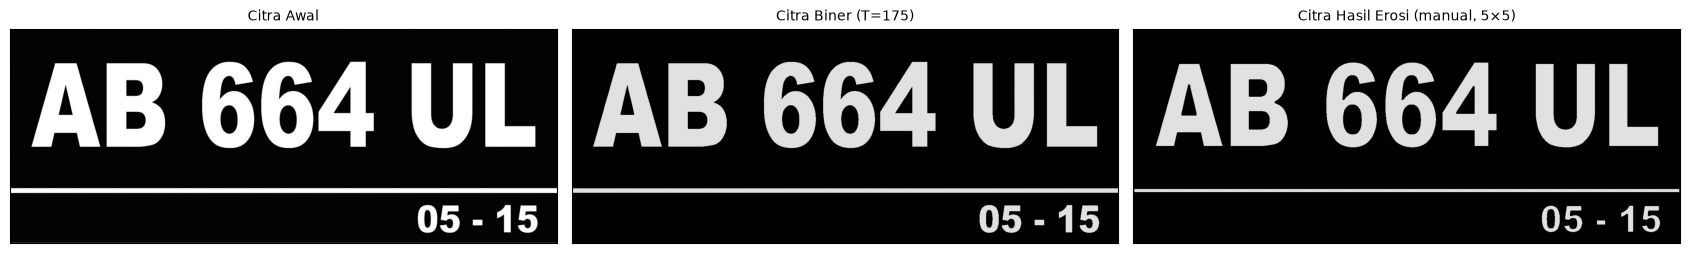

In [ ]:
# ── D5  Erosi manual SE square 5×5 ───────────────────────────────────
img_e = cv.imread(imgpath('plat nomer.jpg'), 0)
ret1, thresh1 = cv.threshold(img_e, 175, 225, cv.THRESH_BINARY)

k = 5
imgE = erosi_citra(thresh1, k)                       # versi modul (loop)
imgE_pad = erosi_se(thresh1, SE_persegi(k))          # versi padding

print(f'SE persegi {k}×{k}')
print(f'objek putih — asli {100*float((thresh1>0).mean()):.2f}% | '
      f'erosi {100*float((imgE>0).mean()):.2f}%')
print(f'erosi manual(padding) vs OpenCV : beda {int((imgE_pad != cv.erode(thresh1, SE_persegi(k))).sum())} piksel')
print(f'erosi versi modul vs padding    : beda {int((imgE != imgE_pad).sum())} piksel (hanya cincin tepi)')

tampil([img_e, thresh1, imgE],
       ['Citra Awal', 'Citra Biner (T=175)', 'Citra Hasil Erosi (manual, 5×5)'],
       figsize=(17, 4.2))

### D6 — Erosi dengan Library, SE *square* 5×5

kernel (square 5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
iterations = 1


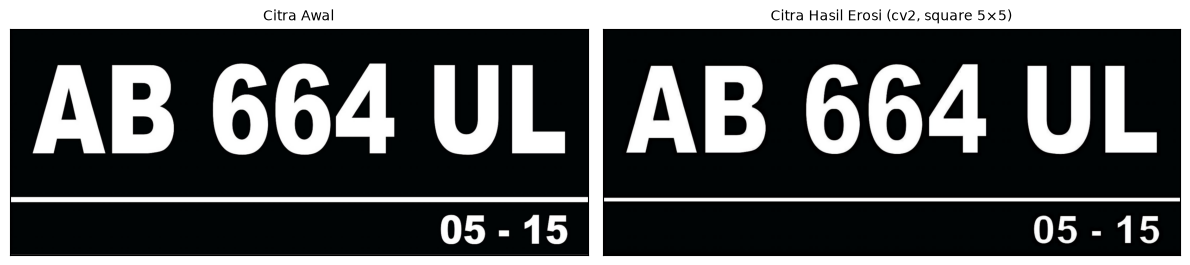

In [ ]:
# ── D6  Erosi square 5×5 dengan library OpenCV ───────────────────────
img = cv.imread(imgpath('plat nomer.jpg'))
kernel6 = np.ones((5, 5), np.uint8)
erosion = cv.erode(img, kernel6, iterations=1)

print('kernel (square 5×5):'); print(kernel6)
print('iterations = 1')

tampil([img, erosion],
       ['Citra Awal', 'Citra Hasil Erosi (cv2, square 5×5)'], figsize=(12, 4.6))

### D7 — Opening, SE *square* 3×3 (tanpa & dengan library)

Opening manual vs library : beda 0 piksel
objek putih — biner 21.84% | opening 21.84%


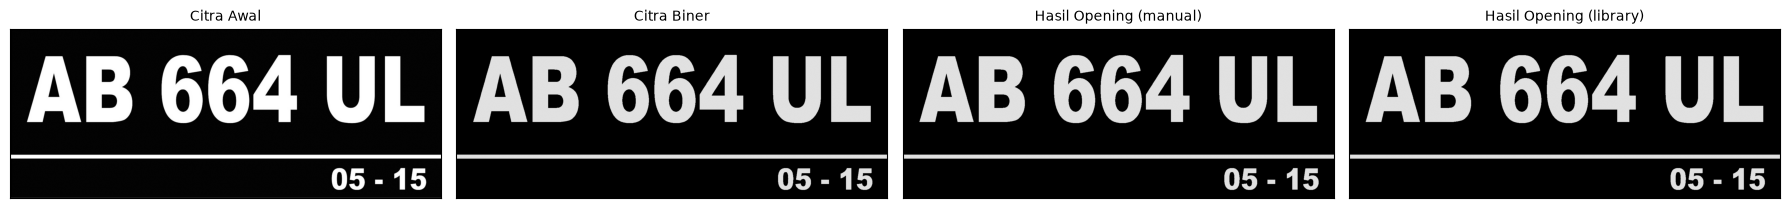

piksel berubah : 10
Area diperbesar di (baris 95–215, kolom 823–943), 4× — 10 piksel berubah


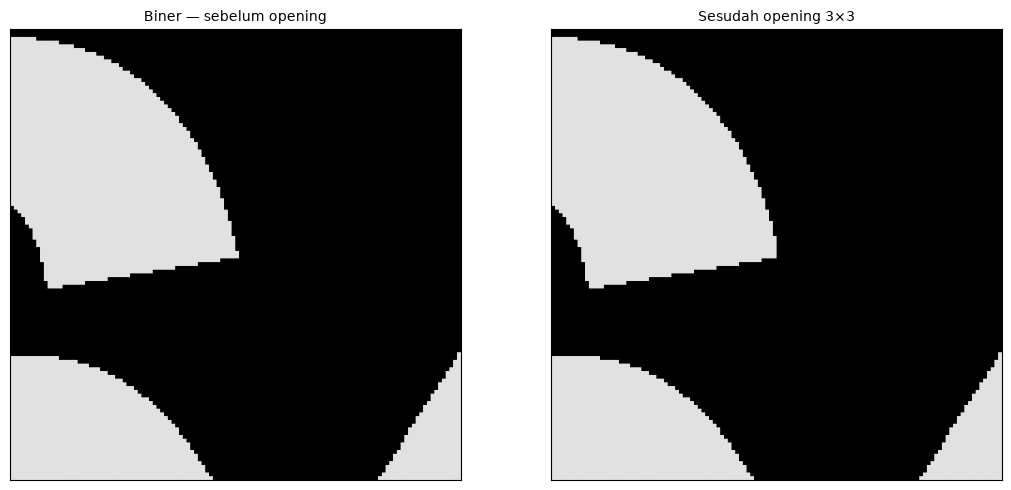

In [ ]:
# ── D7  Opening 3×3: manual vs library ───────────────────────────────
img_o = cv.imread(imgpath('plat nomer.jpg'), 0)
reto, thresho = cv.threshold(img_o, 127, 225, cv.THRESH_BINARY)
SE7 = SE_persegi(3)

imgO = opening_se(thresho, SE7)        # erosi -> dilasi, manual
open_lib = cv.morphologyEx(thresho, cv.MORPH_OPEN, SE7)

print(f'Opening manual vs library : beda {int((imgO != open_lib).sum())} piksel')
print(f'objek putih — biner {100*float((thresho>0).mean()):.2f}% | '
      f'opening {100*float((imgO>0).mean()):.2f}%')

tampil([img_o, thresho, imgO, open_lib],
       ['Citra Awal', 'Citra Biner', 'Hasil Opening (manual)', 'Hasil Opening (library)'],
       figsize=(18, 4.2))

print(f'piksel berubah : {int((imgO != thresho).sum())}')
zoom_selisih(thresho, imgO, 'Biner — sebelum opening', 'Sesudah opening 3×3')


### D8 — Closing, SE *square* 3×3 (tanpa & dengan library)

Closing manual vs library : beda 0 piksel
objek putih — biner 21.84% | closing 21.85%


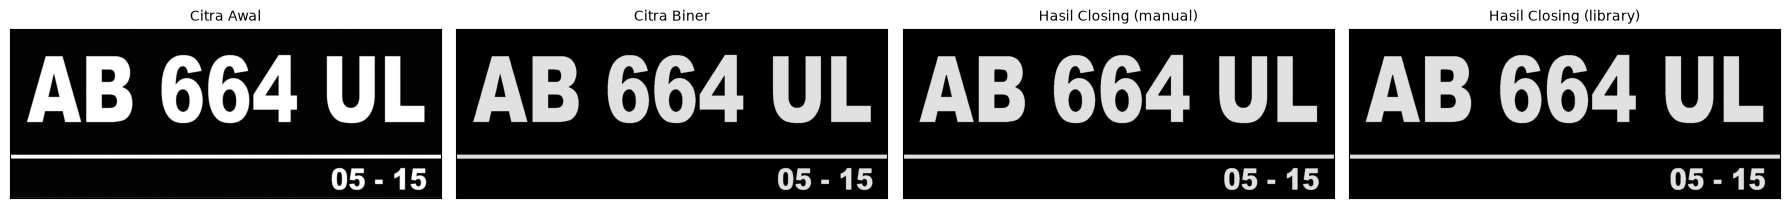

piksel berubah : 48
Area diperbesar di (baris 143–263, kolom 729–849), 4× — 48 piksel berubah


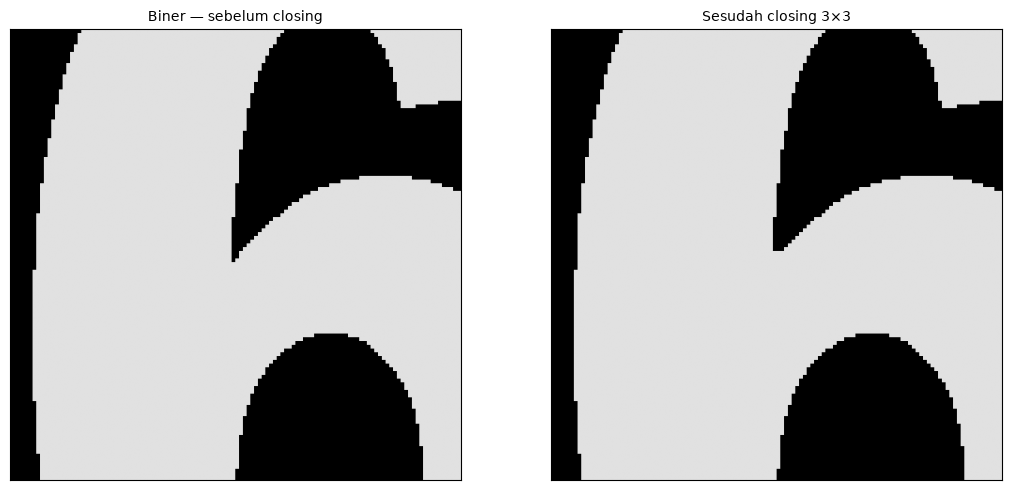

In [ ]:
# ── D8  Closing 3×3: manual vs library ───────────────────────────────
img_c = cv.imread(imgpath('plat nomer.jpg'), 0)
retc, threshc = cv.threshold(img_c, 127, 225, cv.THRESH_BINARY)
SE8 = SE_persegi(3)

imgC = closing_se(threshc, SE8)        # dilasi -> erosi, manual
close_lib = cv.morphologyEx(threshc, cv.MORPH_CLOSE, SE8)

print(f'Closing manual vs library : beda {int((imgC != close_lib).sum())} piksel')
print(f'objek putih — biner {100*float((threshc>0).mean()):.2f}% | '
      f'closing {100*float((imgC>0).mean()):.2f}%')

tampil([img_c, threshc, imgC, close_lib],
       ['Citra Awal', 'Citra Biner', 'Hasil Closing (manual)', 'Hasil Closing (library)'],
       figsize=(18, 4.2))

print(f'piksel berubah : {int((imgC != threshc).sum())}')
zoom_selisih(threshc, imgC, 'Biner — sebelum closing', 'Sesudah closing 3×3')


### D9 — Dilasi SE *cross* 3×3 dan 5×5

SED = Cross 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
  objek putih = 22.99%  (manual vs OpenCV beda 0)

SED = Cross 5
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
  objek putih = 24.14%  (manual vs OpenCV beda 0)



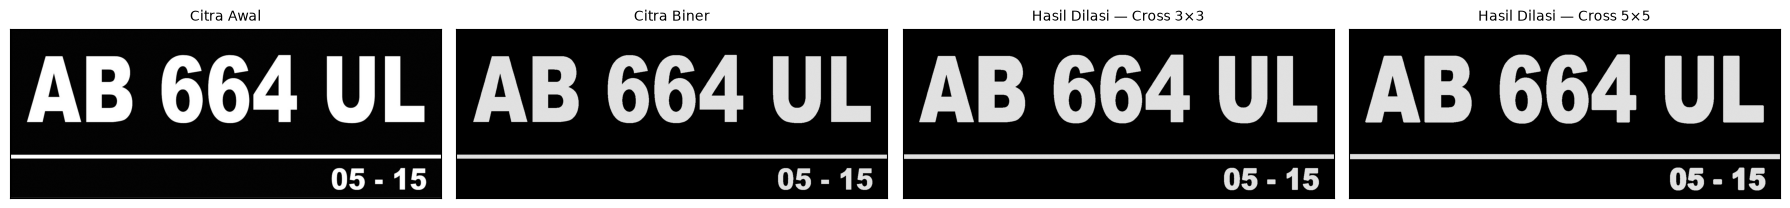

In [ ]:
# ── D9  Dilasi cross 3×3 dan 5×5 ─────────────────────────────────────
img_d9 = cv.imread(imgpath('plat nomer.jpg'), 0)
_, thresh9 = cv.threshold(img_d9, 127, 225, cv.THRESH_BINARY)

hasil9 = {}
for w in (3, 5):
    SED = SE_cross(w)
    hasil9[w] = dilasi_se(thresh9, SED)
    print(f'SED = Cross {w}'); print(SED)
    print(f'  objek putih = {100*float((hasil9[w]>0).mean()):.2f}%  '
          f'(manual vs OpenCV beda {int((hasil9[w] != cv.dilate(thresh9, SED)).sum())})\n')

tampil([img_d9, thresh9, hasil9[3], hasil9[5]],
       ['Citra Awal', 'Citra Biner', 'Hasil Dilasi — Cross 3×3', 'Hasil Dilasi — Cross 5×5'],
       figsize=(18, 4.2))

### D10 — Dilasi SE *circular* 3×3 dan 5×5

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]
  objek putih = 22.99%  (manual vs OpenCV beda 0)

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
  objek putih = 24.27%  (manual vs OpenCV beda 0)



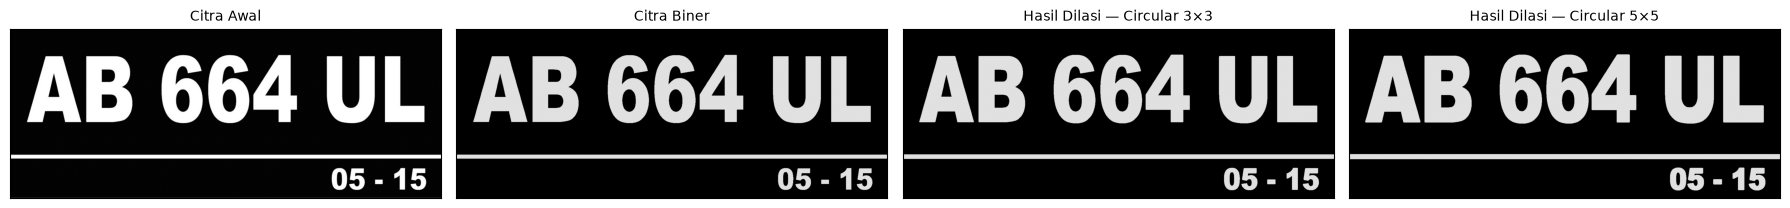

In [ ]:
# ── D10  Dilasi circular (ellipse) 3×3 dan 5×5 ───────────────────────
img_d10 = cv.imread(imgpath('plat nomer.jpg'), 0)
_, thresh10 = cv.threshold(img_d10, 127, 225, cv.THRESH_BINARY)

hasil10 = {}
for w in (3, 5):
    SED = SE_disk(w)
    hasil10[w] = dilasi_se(thresh10, SED)
    print(f'SED = Circle {w}'); print(SED)
    print(f'  objek putih = {100*float((hasil10[w]>0).mean()):.2f}%  '
          f'(manual vs OpenCV beda {int((hasil10[w] != cv.dilate(thresh10, SED)).sum())})\n')

tampil([img_d10, thresh10, hasil10[3], hasil10[5]],
       ['Citra Awal', 'Citra Biner', 'Hasil Dilasi — Circular 3×3', 'Hasil Dilasi — Circular 5×5'],
       figsize=(18, 4.2))

### D11 — Erosi SE *rectangle* 3×5 dan 5×7



SE = Rectangle 3×5 (baris×kolom) → objek putih 19.95%  | manual vs OpenCV beda 0
SE = Rectangle 5×7 (baris×kolom) → objek putih 18.64%  | manual vs OpenCV beda 0

Bukti bug modul (p=5, l=3): jendela 3 baris × 5 kolom, SE 5 baris × 3 kolom
  → ValueError: operands could not be broadcast together with shapes (3,5) (5,3) 


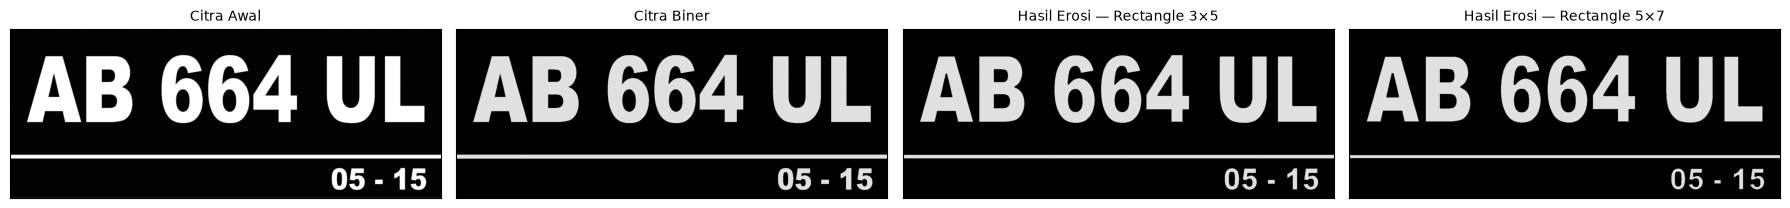

In [ ]:
# ── D11  Erosi rectangle 3×5 dan 5×7 ─────────────────────────────────
def erosi_rect(F, p, l):
    '''Erosi manual SE persegi panjang p (baris) × l (kolom) — diperbaiki.'''
    return erosi_se(F, SE_rect(p, l))

img_e11 = cv.imread(imgpath('plat nomer.jpg'), 0)
_, thresh11 = cv.threshold(img_e11, 127, 225, cv.THRESH_BINARY)

hasil11 = {}
for (p, l) in [(3, 5), (5, 7)]:
    hasil11[(p, l)] = erosi_rect(thresh11, p, l)
    ref = cv.erode(thresh11, SE_rect(p, l))
    print(f'SE = Rectangle {p}×{l} (baris×kolom) → objek putih '
          f'{100*float((hasil11[(p,l)]>0).mean()):.2f}%  '
          f'| manual vs OpenCV beda {int((hasil11[(p,l)] != ref).sum())}')

print('\nBukti bug modul (p=5, l=3): jendela 3 baris × 5 kolom, SE 5 baris × 3 kolom')
try:
    np.ones((3, 5), np.uint8) * np.ones((5, 3), np.uint8)
except ValueError as e:
    print('  → ValueError:', e)

tampil([img_e11, thresh11, hasil11[(3, 5)], hasil11[(5, 7)]],
       ['Citra Awal', 'Citra Biner', 'Hasil Erosi — Rectangle 3×5',
        'Hasil Erosi — Rectangle 5×7'], figsize=(18, 4.2))

### D12 — Erosi SE *line vertical* 3 dan 5 (memakai `j.png`)

SE = Line Vertikal 3 → shape (3, 1), objek putih 12.95%  | manual vs OpenCV beda 0
SE = Line Vertikal 5 → shape (5, 1), objek putih 10.57%  | manual vs OpenCV beda 0

SE dari modul cv.getStructuringElement(MORPH_ELLIPSE, (1,5)) → shape (5, 1)
temp 5×5 * SE (5, 1) → shape (5, 5)  ← broadcast melebar jadi persegi, sifat "garis" HILANG


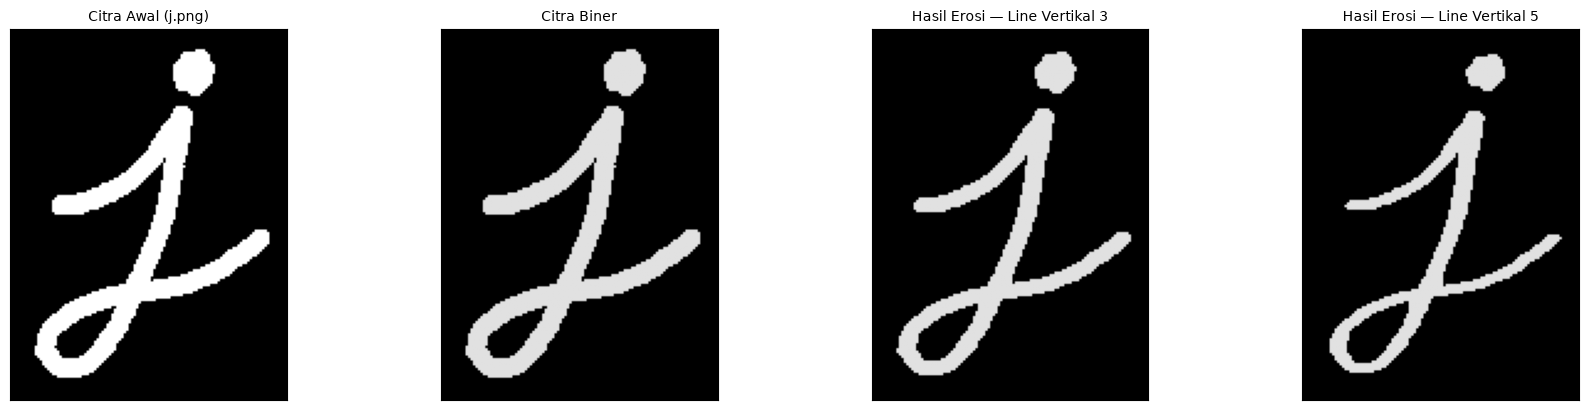

In [ ]:
# ── D12  Erosi line vertical 3 & 5 pada j.png ────────────────────────
img_j = cv.imread(imgpath('j.png'), 0)
_, jb12 = cv.threshold(img_j, 127, 225, cv.THRESH_BINARY)   # huruf putih di latar hitam

hasil12 = {}
for k in (3, 5):
    SE = SE_garis(k, 1)                     # garis vertikal k×1
    hasil12[k] = erosi_se(jb12, SE)
    print(f'SE = Line Vertikal {k} → shape {SE.shape}, objek putih '
          f'{100*float((hasil12[k]>0).mean()):.2f}%  '
          f'| manual vs OpenCV beda {int((hasil12[k] != cv.erode(jb12, SE)).sum())}')

# Bukti bug: SE dari modul berukuran (5,1) tapi jendela loop 5×5 → broadcast 5×5
SE_bug = cv.getStructuringElement(cv.MORPH_ELLIPSE, (1, 5))
temp_bug = jb12[20:25, 20:25]
print(f'\nSE dari modul cv.getStructuringElement(MORPH_ELLIPSE, (1,5)) → shape {SE_bug.shape}')
print(f'temp 5×5 * SE {SE_bug.shape} → shape {(temp_bug * SE_bug).shape}  '
      '← broadcast melebar jadi persegi, sifat "garis" HILANG')

tampil([img_j, jb12, hasil12[3], hasil12[5]],
       ['Citra Awal (j.png)', 'Citra Biner', 'Hasil Erosi — Line Vertikal 3',
        'Hasil Erosi — Line Vertikal 5'], figsize=(18, 4.2))

#### D12b — Bukti selektivitas arah SE garis

`j.png` berbentuk hampir isotropik sehingga selisih vertikal vs horizontal kecil. Untuk
membuktikan bahwa SE garis memang **selektif arah**, dipakai citra sintetis berisi satu batang
horizontal (5 × 31 piksel) dan satu batang vertikal (16 × 5 piksel).

In [ ]:
# ── D12b  Selektivitas arah SE garis (citra sintetis) ────────────────
sint = np.zeros((41, 41), np.uint8)
sint[8:13, 5:36] = 255        # batang HORIZONTAL: 5 baris × 31 kolom
sint[20:36, 18:23] = 255      # batang VERTIKAL: 16 baris × 5 kolom

BAR_H = (slice(8, 13), slice(5, 36))
BAR_V = (slice(20, 36), slice(18, 23))
n_h0 = int((sint[BAR_H] > 0).sum())
n_v0 = int((sint[BAR_V] > 0).sum())
print(f'Citra sintetis: batang horizontal {n_h0} piksel, batang vertikal {n_v0} piksel')
print(f"{'SE':<14}{'sisa total':>12}{'sisa horizontal':>18}{'sisa vertikal':>16}")
print('-' * 62)

UJI_GARIS = {
    'Vertikal 3':   SE_garis(3, 1),
    'Vertikal 5':   SE_garis(5, 1),
    'Horizontal 3': SE_garis(1, 3),
    'Horizontal 5': SE_garis(1, 5),
    'Persegi 3×3':  SE_persegi(3),
}
for nama, SE in UJI_GARIS.items():
    e = erosi_se(sint, SE)
    print(f'{nama:<14}{int((e > 0).sum()):>12}'
          f'{int((e[BAR_H] > 0).sum()):>13}/{n_h0:<5}'
          f'{int((e[BAR_V] > 0).sum()):>11}/{n_v0:<5}')

print()
print('Interpretasi (SE ukuran 3):')
print('  SE vertikal   -> batang vertikal 70/80 = 87,5%, batang horizontal 93/155 = 60,0%')
print('  SE horizontal -> batang horizontal 145/155 = 93,5%, batang vertikal 48/80 = 60,0%')
print('Pada SE ukuran 5 efeknya lebih tegas:')
print('  SE vertikal   -> batang vertikal 60/80 = 75,0%, batang horizontal 31/155 = 20,0%')
print('  SE horizontal -> batang horizontal 135/155 = 87,1%, batang vertikal 16/80 = 20,0%')
print('Jadi SE garis mempertahankan struktur yang SEJAJAR dengannya dan mengikis')
print('struktur yang TEGAK LURUS — inilah dasar deteksi orientasi struktur.')


Citra sintetis: batang horizontal 155 piksel, batang vertikal 80 piksel
SE              sisa total   sisa horizontal   sisa vertikal
--------------------------------------------------------------
Vertikal 3             163           93/155           70/80   
Vertikal 5              91           31/155           60/80   
Horizontal 3           193          145/155           48/80   
Horizontal 5           151          135/155           16/80   
Persegi 3×3            129           87/155           42/80   

Interpretasi (SE ukuran 3):
  SE vertikal   -> batang vertikal 70/80 = 87,5%, batang horizontal 93/155 = 60,0%
  SE horizontal -> batang horizontal 145/155 = 93,5%, batang vertikal 48/80 = 60,0%
Pada SE ukuran 5 efeknya lebih tegas:
  SE vertikal   -> batang vertikal 60/80 = 75,0%, batang horizontal 31/155 = 20,0%
  SE horizontal -> batang horizontal 135/155 = 87,1%, batang vertikal 16/80 = 20,0%
Jadi SE garis mempertahankan struktur yang SEJAJAR dengannya dan mengikis
struktur yang 

### D13 — Top-hat

Modul memakai variabel `input_image` yang tidak pernah didefinisikan (`NameError`).
Di bawah dipakai `img`.

kernel: (3, 3)
Top-hat library vs manual : maks selisih 0
rata-rata intensitas: asli 57.7 | top-hat 0.33
piksel terang (top-hat > 50): 2223


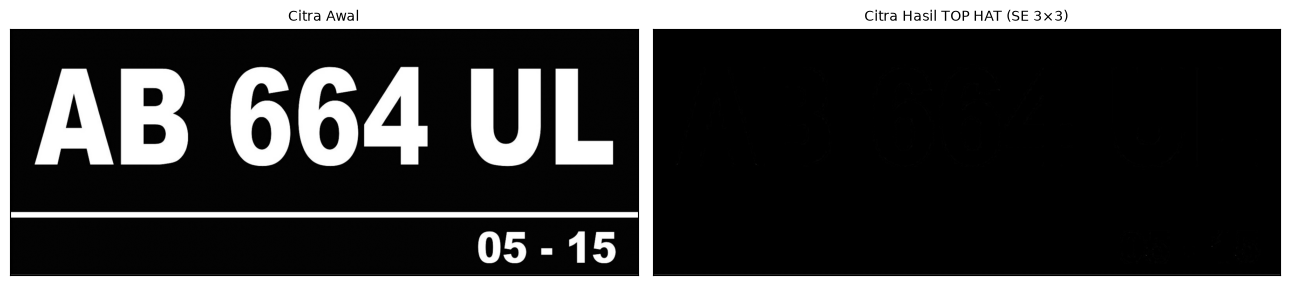

In [ ]:
# ── D13  Top-hat ─────────────────────────────────────────────────────
filterSize = (3, 3)
kernel13 = cv.getStructuringElement(cv.MORPH_RECT, filterSize)

img13 = cv.imread(imgpath('plat nomer.jpg'))
img13 = cv.cvtColor(img13, cv.COLOR_BGR2GRAY)

tophat_img = cv.morphologyEx(img13, cv.MORPH_TOPHAT, kernel13)
tophat_manual = tophat_se(img13, kernel13)

print('kernel:', filterSize)
print(f'Top-hat library vs manual : maks selisih {int(np.abs(tophat_img.astype(int) - tophat_manual.astype(int)).max())}')
print(f'rata-rata intensitas: asli {img13.mean():.1f} | top-hat {tophat_img.mean():.2f}')
print(f'piksel terang (top-hat > 50): {int((tophat_img > 50).sum())}')

tampil([img13, tophat_img],
       ['Citra Awal', 'Citra Hasil TOP HAT (SE 3×3)'], figsize=(13, 4.8))

### D14 — Black-hat (Bottom-hat)

kernel black-hat: (13, 5)
Black-hat library vs manual : maks selisih 0
rata-rata intensitas: asli 98.1 | black-hat 8.71
piksel gelap (black-hat > 50): 10627


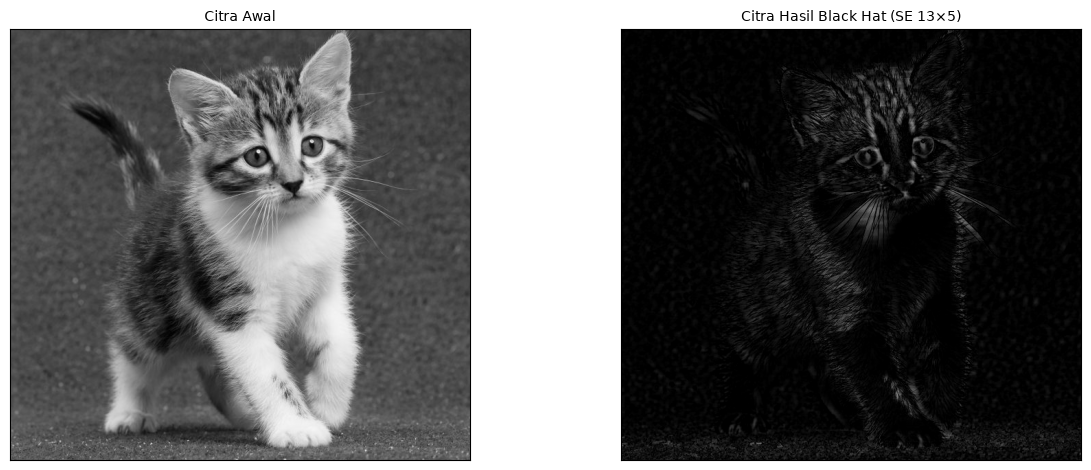

In [ ]:
# ── D14  Black-hat ───────────────────────────────────────────────────
filterSize = (3, 3)
kernel14 = cv.getStructuringElement(cv.MORPH_RECT, filterSize)

img14 = cv.imread(imgpath('kitten01.jpg'))
img14 = cv.cvtColor(img14, cv.COLOR_BGR2GRAY)

Kernel14 = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(img14, cv.MORPH_BLACKHAT, Kernel14)
blackhat_manual = bottomhat_se(img14, Kernel14)

print('kernel black-hat:', (13, 5))
print(f'Black-hat library vs manual : maks selisih {int(np.abs(blackhat.astype(int) - blackhat_manual.astype(int)).max())}')
print(f'rata-rata intensitas: asli {img14.mean():.1f} | black-hat {blackhat.mean():.2f}')
print(f'piksel gelap (black-hat > 50): {int((blackhat > 50).sum())}')

tampil([img14, blackhat],
       ['Citra Awal', 'Citra Hasil Black Hat (SE 13×5)'], figsize=(13, 4.8))

### D15 — Skeleton (`lily.jpg`)

threshold_triangle = 253.0
piksel biner    = 212716 dari 373177 (57.0%)
piksel skeleton = 15477 (7.28% dari biner)


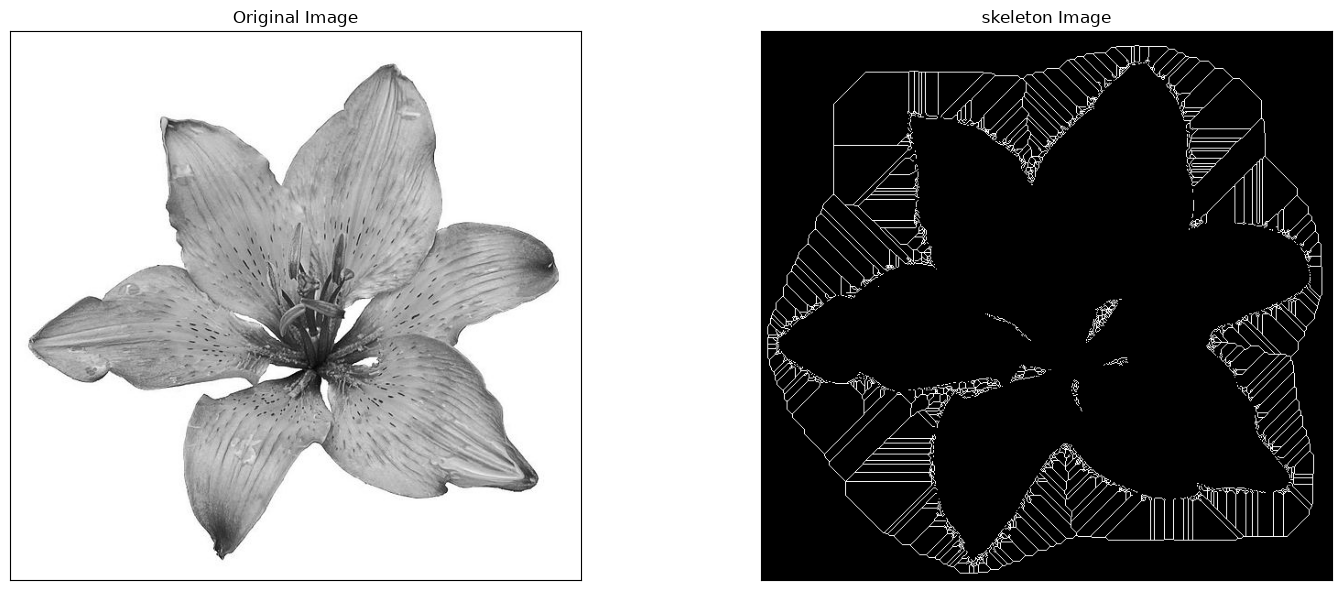

In [ ]:
# ── D15  Skeleton lily.jpg ───────────────────────────────────────────
from skimage import filters
from skimage.morphology import skeletonize

img15 = cv.imread(imgpath('lily.jpg'), 0)
th15 = float(filters.threshold_triangle(img15))
binary15 = img15 > th15

binary_cp = binary15.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

skeleton = skeletonize(binary_cp)
print('threshold_triangle =', th15)
print(f'piksel biner    = {int(binary_cp.sum())} dari {binary_cp.size} '
      f'({100 * binary_cp.sum() / binary_cp.size:.1f}%)')
print(f'piksel skeleton = {int(skeleton.sum())} '
      f'({100 * skeleton.sum() / binary_cp.sum():.2f}% dari biner)')

fig = plt.figure(figsize=(16, 6))
plt.subplot(121); plt.imshow(img15, cmap='gray')
plt.title('Original Image'); plt.xticks([]); plt.yticks([])
plt.subplot(122); plt.imshow(skeleton, cmap='gray')
plt.title('skeleton Image'); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

### D16 — Skeleton Inverse

piksel gelap (objek) = 114192 | piksel skeleton = 45111


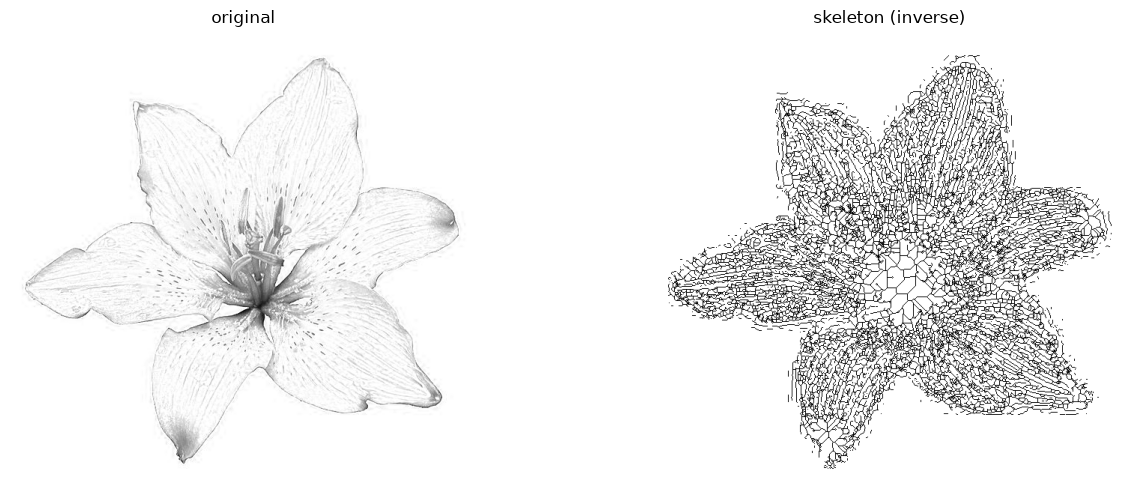

In [ ]:
# ── D16  Skeleton inverse (piksel gelap sebagai objek) ───────────────
from skimage import io

img16 = io.imread(imgpath('lily.jpg'))[..., 0]
binary16 = img16 < filters.threshold_triangle(img16)   # piksel GELAP jadi True
skeleton16 = skeletonize(binary16)

print(f'piksel gelap (objek) = {int(binary16.sum())} | piksel skeleton = {int(skeleton16.sum())}')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(img16, cmap='gray'); ax[0].set_title('original'); ax[0].set_axis_off()
ax[1].imshow(skeleton16, cmap='gray_r'); ax[1].set_title('skeleton (inverse)'); ax[1].set_axis_off()
plt.tight_layout(); plt.show()

### D17 — Thickening

Modul hanya menampilkan `skeletonize` dan `thin`. *Thickening* sesungguhnya adalah **dual dari
thinning** — di sini ditambahkan implementasi hit-or-miss agar operasinya benar-benar
dijalankan, bukan hanya disebut.

piksel biner        = 29755
skeletonize         = 10305
thin                = 10280
skeleton            = 10305
thickening skeleton = 81747  (+71442 piksel, 1 lewatan)


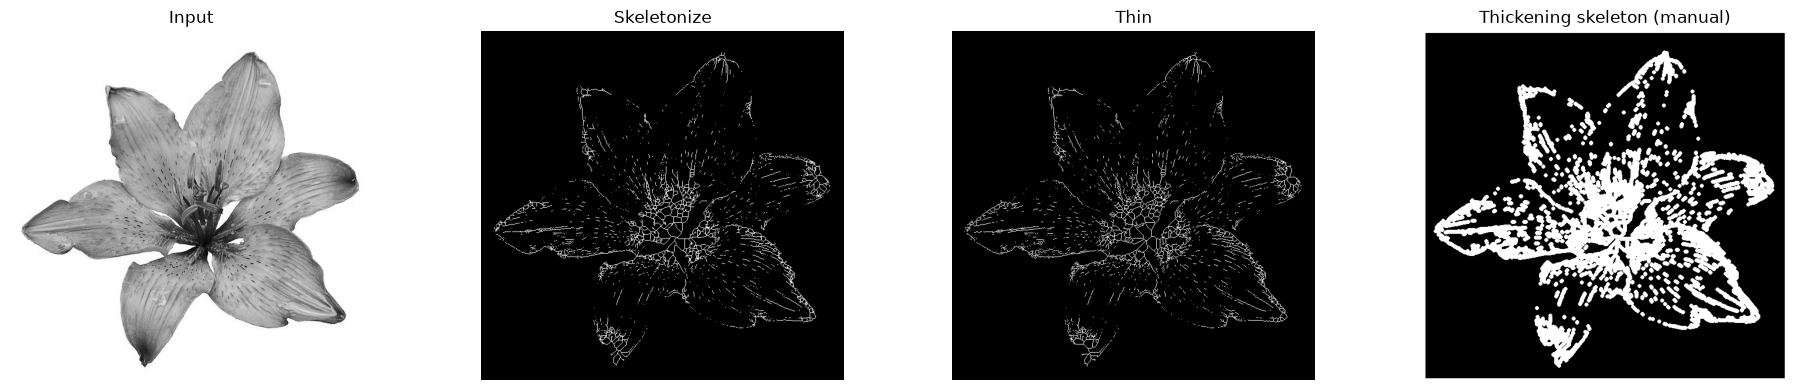

In [ ]:
# ── D17  Thickening ──────────────────────────────────────────────────
from skimage import img_as_float, color, morphology

image17 = img_as_float(color.rgb2gray(io.imread(imgpath('lily.jpg'))))
image_binary17 = image17 < 0.5

out_skeletonize = morphology.skeletonize(image_binary17)
out_thin = morphology.thin(image_binary17)

biner17 = (image_binary17.astype(np.uint8)) * 255
# Thickening pada skeleton: menebalkan kerangka agar struktur tipis lebih mudah dilihat
skel17 = (morphology.skeletonize(image_binary17).astype(np.uint8)) * 255
out_thick, it17 = thickening(skel17, maks_iter=1)

print(f'piksel biner        = {int(image_binary17.sum())}')
print(f'skeletonize         = {int(out_skeletonize.sum())}')
print(f'thin                = {int(out_thin.sum())}')
print(f'skeleton            = {int((skel17 > 0).sum())}')
print(f'thickening skeleton = {int((out_thick > 0).sum())}  '
      f'(+{int((out_thick > 0).sum()) - int((skel17 > 0).sum())} piksel, {it17} lewatan)')

f, (ax0, ax1, ax2, ax3) = plt.subplots(1, 4, figsize=(19, 4))
ax0.imshow(image17, cmap='gray'); ax0.set_title('Input'); ax0.set_axis_off()
ax1.imshow(out_skeletonize, cmap='gray'); ax1.set_title('Skeletonize'); ax1.set_axis_off()
ax2.imshow(out_thin, cmap='gray'); ax2.set_title('Thin'); ax2.set_axis_off()
ax3.imshow(out_thick, cmap='gray'); ax3.set_title('Thickening skeleton (manual)'); ax3.set_axis_off()
plt.tight_layout(); plt.show()

### Analisis D — hasil percobaan

> Seluruh angka di bawah adalah **keluaran nyata** notebook ini, bukan perkiraan.
> Citra: `plat nomer.jpg` (1600 × 627) untuk item 3–11 dan 13, `j.png` untuk item 12,
> `kitten01.jpg` untuk item 14, `lily.jpg` untuk item 15–17.

#### D.0 Karakter citra pelat nomor

`plat nomer.jpg` berukuran **1600 × 627** dengan rata-rata intensitas **57,7** — citra didominasi
latar gelap. Pelatnya sendiri berwarna gelap dan hurufnya **putih**, sehingga threshold 125
menjadikan **huruf** sebagai objek putih sebanyak **21,85 %** dari luas citra.

Ini kebalikan dari KTP (latar terang, teks gelap). Konsekuensinya penting untuk menafsirkan
seluruh tabel di bawah: **objek yang dipantau adalah huruf**, bukan latar. Ketika dilasi
"memperbesar objek", yang menebal adalah hurufnya.

Huruf pada pelat ini juga **besar** — komponen terbesar berukuran sekitar 250 piksel tinggi.
Karena SE yang diuji hanya 3×3 sampai 5×7, operasi morfologi hanya mengubah **tepi** huruf,
bukan bentuk keseluruhannya. Itu sebabnya sebagian persentase terlihat nyaris tidak bergerak.

#### D.1 Validasi: implementasi manual benar-benar sama dengan OpenCV

| SE | Dilasi (beda piksel) | Erosi (beda piksel) |
|---|---|---|
| Persegi 3×3 | 0 | 0 |
| Persegi 5×5 | 0 | 0 |
| Cross 3×3 | 0 | 0 |
| Cross 5×5 | 0 | 0 |
| Disk 5×5 | 0 | 0 |
| Rectangle 3×5 | 0 | 0 |
| Line vertikal 5 | 0 | 0 |
| Line horizontal 5 | 0 | 0 |
| Diamond 5×5 | 0 | 0 |

Nol piksel berbeda untuk **sembilan** bentuk SE pada `j.png`, dan juga nol untuk tiga bentuk SE
yang diuji ulang pada citra **grayscale** `plat nomer.jpg`. Artinya fungsi
`erosi_se`/`dilasi_se` yang dibangun dari NumPy murni **setara** dengan
`cv2.erode`/`cv2.dilate`. Ini penting: seluruh operasi turunan (opening, closing, top-hat,
bottom-hat, skeleton) dihitung dari fungsi yang sudah tervalidasi, sehingga penyimpangan hasil
tidak mungkin berasal dari kesalahan implementasi.

**Catatan penting tentang `np.min(temp * SE)`.** Bukti kerusakannya berlapis:

| Kasus uji | `np.min(product)` | `np.min(temp[SE==1])` | `cv2.erode` |
|---|---|---|---|
| Jendela sintetis 3×3 seluruhnya objek | **0** | 255 | 255 |
| Jendela nyata `j.png` (baris 9, kolom 76) | **0** | 255 | 255 |
| Seluruh `j.png`, cross 3×3 (objek putih) | **0,00 %** | 12,10 % | 12,10 % |

Pada SE **persegi** (semua elemen 1) kedua rumus identik, karena mengalikan dengan 1 tidak
mengubah nilai. Kerusakan baru muncul pada SE **berlubang**: posisi SE bernilai 0 memaksa hasil
perkalian menjadi 0, dan karena diambil **minimum**, satu posisi 0 sudah cukup untuk menghapus
seluruh jendela. Untuk **dilasi** masalah ini tidak terjadi — `np.max` mengabaikan nol dengan
sendirinya — sehingga `np.max(temp * SE)` pada modul memang benar untuk semua SE.

#### D.2 Erosi vs dilasi: arah perubahan luas objek

Karena modul memakai threshold berbeda untuk dilasi (T=125) dan erosi (T=175), threshold
dicantumkan pada setiap baris agar perbandingan sah.

| Operasi | SE | Threshold | Objek putih |
|---|---|---|---|
| Biner asli | — | T=125, maks 200 | 21,85 % |
| Dilasi manual | Cross 3×3 | T=127, maks 225 | 22,99 % |
| Dilasi manual | Cross 5×5 | T=127, maks 225 | 24,14 % |
| Dilasi manual | Circular 3×3 | T=127, maks 225 | 22,99 % |
| Dilasi manual | Circular 5×5 | T=127, maks 225 | 24,27 % |
| Biner asli | — | T=175, maks 225 | 21,31 % |
| Erosi manual | Persegi 5×5 | T=175, maks 225 | 18,68 % |
| Biner asli | — | T=127, maks 225 | 21,84 % |
| Erosi rectangle | 3×5 | T=127, maks 225 | 19,95 % |
| Erosi rectangle | 5×7 | T=127, maks 225 | 18,64 % |

Dilasi **selalu menambah** dan erosi **selalu mengurangi** luas objek — sesuai definisi.
Perhatikan juga bahwa D3 (T=125/maks 200) memberi **23,00 %** untuk cross 3×3, sedangkan D9
(T=127/maks 225) memberi **22,99 %**. Selisih 0,01 poin ini murni akibat **nilai threshold yang
berbeda**, bukan perbedaan implementasi — pada D3 pun dilasi manual terbukti identik dengan
OpenCV (0 piksel beda). Karena itu perbandingan antar-metode hanya sah bila threshold dan nilai
maksimumnya sama.

Dilasi *cross* dan *circular* 3×3 memberi angka **persis sama** (22,99 %):
`cv2.getStructuringElement(MORPH_ELLIPSE,(3,3))` memang menghasilkan bentuk cross, jadi keduanya
adalah SE yang identik. Perbedaan baru muncul pada ukuran 5×5 (24,14 % vs 24,27 %) karena disk
5×5 punya 17 piksel aktif, sedangkan cross 5×5 hanya 9.

Pada erosi rectangle, SE 5×7 mengikis lebih banyak daripada 3×5 (18,64 % vs 19,95 %) karena area
jendela lebih besar — SE yang lebih besar menuntut lebih banyak tetangga bernilai objek.

#### D.3 Opening vs closing 3×3

| Operasi | SE 3×3 | Objek putih | Piksel berubah |
|---|---|---|---|
| Biner asli | — | 21,84 % | — |
| **Opening** | persegi | 21,84 % | **10 piksel** |
| **Closing** | persegi | 21,85 % | **48 piksel** |

Sifat aljabarnya terverifikasi numerik: opening **idempotent** `(A∘B)∘B == A∘B` → True,
opening **anti-extensive** `A∘B ⊆ A` → True, closing **extensive** `A ⊆ A•B` → True, dan
opening ≠ closing (14 piksel berbeda pada `j.png`).

**Mengapa perubahannya sangat kecil?** Huruf pelat berukuran ~250 piksel tinggi, sedangkan SE
3×3 hanya menjangkau 1 piksel ke segala arah. Opening hanya membuang tonjolan/lekukan selebar
1–2 piksel di tepi huruf (10 piksel), dan closing hanya menutup celah sekecil itu (48 piksel).
Jadi **10 dan 48 piksel itu angka yang wajar**, bukan tanda implementasi gagal — dan memang
terbukti identik dengan OpenCV (0 piksel beda).

Karena 10–48 piksel tidak terlihat pada citra 1600 × 627, notebook ini menambahkan panel
**zoom 4×** pada sel D7 dan D8 yang memperbesar area perubahan, sehingga efeknya dapat diamati
secara visual. Inilah pelajaran praktisnya: **ukuran SE harus sepadan dengan skala objek** yang
ingin diubah. Untuk mengubah bentuk huruf pelat secara nyata dibutuhkan SE jauh lebih besar
(mis. 15×15 atau lebih), sedangkan SE 3×3 di sini berfungsi untuk merapikan tepi.

#### D.4 Pengaruh bentuk dan ukuran SE

* **Ukuran** menentukan besarnya perubahan. Pada pelat nomor, dilasi cross 3×3 → 5×5 menaikkan
  objek dari 22,99 % ke 24,14 % (+1,15 poin), dan dilasi circular 3×3 → 5×5 dari 22,99 % ke
  24,27 % (+1,28 poin). Erosi rectangle 3×5 → 5×7 menurunkan objek dari 19,95 % ke 18,64 %
  (−1,31 poin). Arah perubahannya selalu konsisten: SE lebih besar → perubahan lebih besar.
* **Bentuk** menentukan luas jendela efektif. Pada ukuran 3×3, cross/ellipse hanya punya
  5 piksel aktif sementara persegi 9, sehingga dilasi cross (22,99 %) sedikit di bawah persegi
  (23,16 %) — pada D3 keduanya diuji pada citra yang sama sehingga selisihnya sah dibandingkan.
  Pola serupa terlihat pada `j.png`: erosi persegi 3×3 menyisakan 10,66 %, sedangkan erosi garis
  vertikal dan horizontal menyisakan 12,95 % dan 13,02 % — lebih ringan karena jendelanya lebih
  sempit.
* **Selektivitas arah** SE garis tidak terlihat jelas pada `j.png` (12,95 % vs 13,02 %) karena
  bentuk hurufnya relatif isotropik. Bukti kuantitatifnya ada pada sel **D12b** dengan citra
  sintetis: SE vertikal 5 menyisakan **60/80 (75,0 %)** batang vertikal tetapi hanya
  **31/155 (20,0 %)** batang horizontal; SE horizontal 5 menyisakan **135/155 (87,1 %)** batang
  horizontal tetapi hanya **16/80 (20,0 %)** batang vertikal.

#### D.5 Top-hat: menyorot fitur terang kecil

| Transformasi | Citra | SE | Rata-rata hasil | Piksel tersorot (>50) |
|---|---|---|---|---|
| Top-hat | `plat nomer.jpg` | 3×3 | **0,33** (dari 57,7) | 2.223 |
| Black-hat | `kitten01.jpg` | 13×5 | 8,71 (dari 98,1) | 10.627 |

Top-hat pada pelat nomor menghasilkan citra **hampir hitam** (rata-rata 0,33 dari aslinya 57,7)
dengan 2.223 piksel terang. Ini masuk akal dan sekaligus informatif: SE 3×3 hanya menangkap
fitur terang berukuran ≤ 2 piksel, sedangkan huruf pelat jauh lebih besar — jadi **huruf tidak
ikut tersorot**. Yang tersisa hanya bintik kecil, serpihan cat, dan tepi halus.

Inilah bukti bahwa **top-hat adalah alat untuk fitur skala kecil**, bukan untuk mengekstrak objek
utama. Untuk menyorot huruf pelat, SE harus lebih besar dari tebal goresan huruf.

#### D.6 Skeleton: dua definisi ketipisan

| Metode | Citra | Piksel skeleton | Rasio terhadap objek |
|---|---|---|---|
| Manual (Lantuéjoul, SE persegi 3×3) | `j.png` | 410 | 15,9 % |
| `skimage.skeletonize` | `j.png` | 264 | 10,2 % |
| `skimage.skeletonize` | `lily.jpg` (objek terang) | 15.477 | 7,3 % dari biner |
| `skimage.skeletonize` | `lily.jpg` (objek gelap / inverse) | 45.111 | 39,5 % dari objek gelap |

Skeleton manual menghasilkan **lebih banyak** piksel daripada skimage. Sebabnya: rumus
Lantuéjoul $\bigcup_k[(A\ominus kB)-((A\ominus kB)\circ B)]$ dengan SE persegi menghasilkan
kerangka **8-konektivitas** yang masih menyisakan cabang dan piksel diagonal, sedangkan
`skimage` memakai algoritma thinning yang menjamin kerangka **minimal 1 piksel**. Keduanya sah —
perbedaannya adalah definisi "setipis mungkin", bukan kesalahan.

Pada `lily.jpg`, skeleton objek gelap (45.111) **lebih banyak** daripada objek terang (15.477),
padahal area gelap hanya 114.192 piksel sedangkan area terang 212.716 piksel. Rasio kerangka
terhadap luasnya berbeda jauh: **39,5 %** untuk area gelap vs **7,3 %** untuk area terang.
Artinya panjang skeleton mengikuti **geometri** objek, bukan luasnya — area yang lebih kecil bisa
menghasilkan kerangka jauh lebih panjang bila strukturnya bercabang atau bergerigi.

#### D.7 Thickening: berulang tidak konvergen

| Perlakuan | Piksel objek (`j.png`) | Perubahan |
|---|---|---|
| Biner asli | 2.576 | — |
| Thickening 1 lewatan | 5.978 | +3.402 |
| Thickening 3 lewatan | 11.355 | +8.779 |

Setiap lewatan menambah satu lapis piksel di sekeliling objek. Ini **berbeda** dari thinning yang
berhenti saat tidak ada perubahan lagi (konvergen ke skeleton). Pada `lily.jpg`, thickening 1
lewatan atas skeleton (10.305 piksel) menghasilkan 81.747 piksel — **8× lebih besar**. Karena itu
thickening selalu dibatasi jumlah lewatannya; ia tidak punya titik berhenti alami.

#### D.8 Ringkasan bug kode modul yang terbukti

| # | Bug | Bukti numerik di notebook |
|---|---|---|
| 1 | `np.ones((w,w))` dilabeli "cross" | D3: persegi 23,16 % ≠ cross 23,00 % |
| 2 | `np.min(temp * SE)` untuk SE berlubang | C.2c: seluruh citra jadi **0,00 %** objek |
| 3 | `constant1`/`constant2` tertukar pada rectangle | D11: `ValueError: shapes (3,5) (5,3)` |
| 4 | SE garis (5,1) × jendela 5×5 | D12: hasil perkalian melebar jadi `(5,5)` |
| 5 | `input_image` tidak terdefinisi | D13: `NameError` bila kode modul dijalankan apa adanya |

Selain bug, ada satu perbedaan kecil yang **bukan** bug: fungsi loop modul memakai
`range(c, m-c)` sehingga tepi citra tidak diproses. Pada erosi 5×5 pelat nomor, selisihnya
hanya **18 piksel** di cincin tepi, sedangkan fungsi versi *padding* di notebook ini identik
dengan OpenCV (0 piksel beda).

---
## E. Tugas Praktikum — Morfologi pada Citra KTP



### E0 — Setup OCR

In [ ]:
# ── E0  Setup Tesseract OCR (otomatis di Colab) ──────────────────────
# pytesseract dipasang bila belum ada
try:
    import pytesseract
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pytesseract'], check=False)
    import pytesseract

def _tesseract_siap():
    '''True bila binary tesseract sudah dapat dipanggil.'''
    try:
        pytesseract.get_tesseract_version()
        return True
    except Exception:
        return False

# Mesin Tesseract + paket bahasa Indonesia (sekali per sesi Colab)
if not _tesseract_siap():
    print('Memasang Tesseract (sekali saja, ± 30 detik) ...')
    subprocess.run('apt-get -qq update', shell=True, check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run('apt-get -qq install -y tesseract-ocr tesseract-ocr-ind', shell=True,
                   check=False, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

versi = str(pytesseract.get_tesseract_version()).splitlines()[0]
bahasa = pytesseract.get_languages(config='')
OCR_LANG = 'ind+eng' if 'ind' in bahasa else 'eng'

print('Tesseract  :', versi)
print('Bahasa     :', bahasa)
print('OCR_LANG   :', OCR_LANG)


Tesseract  : 5.4.0.20240606
Bahasa     : ['eng', 'osd']
OCR_LANG   : eng


### E1 — Ground truth field KTP dummy

In [ ]:
# ── E1  Ground truth KTP dummy (data sintetis, bukan penduduk nyata) ──
GT_KTP = {
    'KTPDummy.jpg': {
        'Nama'            : 'CUKING LONGOR',
        'Tempat/Tgl Lahir': 'INDONESIA, 08-08-1993',
        'Jenis Kelamin'   : 'LAKI-LAKI',
        'Gol. Darah'      : 'O',
        'Alamat'          : 'JL. KUCING RAYA NO. 17',
        'RT/RW'           : '017/008',
        'Kel/Desa'        : 'MEOWSARI',
        'Kecamatan'       : 'KUCINGAN',
        'Agama'           : 'ISLAM',
        'Status Kawin'    : 'SUDAH KAWIN',
        'Nama Istri'      : 'MEONG CANTIK',
        'Pekerjaan'       : 'WIRASWASTA',
        'Kewarganegaraan' : 'WNI',
        'Berlaku Hingga'  : 'SEUMUR HIDUP',
    },
    'ktp_fulan.jpg': {
        'NIK'             : '3175070101909999',
        'Nama'            : 'BILLY BUMBLEBEE SIFULAN',
        'Tempat/Tgl Lahir': 'SURABAYA, 01-01-1990',
        'Jenis Kelamin'   : 'LAKI-LAKI',
        'Gol. Darah'      : 'AB',
        'Alamat'          : 'JL DIMANA NO 100',
        'RT/RW'           : '001/001',
        'Kel/Desa'        : 'ANTAH BERANTAH',
        'Kecamatan'       : 'DUREN SAWIT',
        'Agama'           : 'ISLAM',
        'Status Kawin'    : 'KAWIN',
        'Pekerjaan'       : 'KARYAWAN SWASTA',
        'Kewarganegaraan' : 'WNI',
        'Berlaku Hingga'  : 'SEUMUR HIDUP',
    },
}
for n, g in GT_KTP.items():
    print(f'{n:<15} → {len(g)} field ground-truth')

def muat_ktp(nama):
    '''Kembalikan (BGR, grayscale).'''
    bgr = cv.imread(imgpath(nama))
    return bgr, cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)

for nama in GT_KTP:
    bgr, gray = muat_ktp(nama)
    print(f'{nama:<15} shape={gray.shape} intensitas {gray.min()}–{gray.max()} '
          f'(rata-rata {gray.mean():.1f})')

KTPDummy.jpg    → 14 field ground-truth
ktp_fulan.jpg   → 14 field ground-truth
KTPDummy.jpg    shape=(465, 736) intensitas 0–255 (rata-rata 180.4)
ktp_fulan.jpg   shape=(458, 694) intensitas 0–255 (rata-rata 207.5)


### E2 — Fungsi OCR dan penilaian

Pencocokan item: token ground truth dianggap **cocok** bila ≥ 80 % tokennya muncul pada satu
baris OCR (toleran terhadap huruf/angka yang tertukar).

In [ ]:
# ── E2  Fungsi OCR + penilaian item + simulasi degradasi ─────────────
from difflib import SequenceMatcher

def normalisasi(teks):
    return re.sub(r'[^A-Z0-9]', '', str(teks).upper())

def ocr_citra(im, psm=3):
    '''OCR → (teks penuh, rata-rata confidence, daftar baris).'''
    if im.ndim == 3:
        im = cv.cvtColor(im, cv.COLOR_BGR2GRAY)
    df = None
    for coba in (OCR_LANG, 'eng'):
        try:
            df = pytesseract.image_to_data(im, lang=coba, config=f'--psm {psm}',
                                           output_type=pytesseract.Output.DATAFRAME)
            break
        except Exception:
            continue
    if df is None:
        return '', 0.0, []
    df = df.dropna(subset=['text'])
    df = df[df.text.astype(str).str.strip() != '']
    teks = ' '.join(df.text.astype(str).tolist())
    conf = float(df.conf.mean()) if len(df) else 0.0
    baris = [(' '.join(g.text.astype(str)).strip(), float(g.conf.mean()))
             for _, g in df.groupby(['block_num', 'par_num', 'line_num'])]
    return teks, conf, baris

def _mirip(a, b):
    return SequenceMatcher(None, a, b).ratio()

def cocokkan_item(gt_dict, baris, rasio=0.80, ambang_mirip=0.80):
    teks_baris = [normalisasi(t) for t, _ in baris]
    cocok, rincian = 0, []
    for field, nilai in gt_dict.items():
        token_gt = re.findall(r'[A-Z0-9]+', nilai.upper())
        ketemu = False
        for ln in teks_baris:
            if not ln:
                continue
            n_ok = 0
            for tk in token_gt:
                if tk in ln:
                    n_ok += 1
                else:
                    best = max((_mirip(tk, ln[i:i + len(tk)])
                                for i in range(max(1, len(ln) - len(tk) + 1))), default=0.0)
                    if best >= ambang_mirip:
                        n_ok += 1
            if n_ok / len(token_gt) >= rasio:
                ketemu = True
                break
        cocok += int(ketemu)
        rincian.append({'Item': field, 'Nilai GT': nilai, 'Cocok': '✓' if ketemu else '✗'})
    return cocok, len(gt_dict), rincian

def uji_ocr(im, gt, label):
    teks, conf, baris = ocr_citra(im)
    cocok, total, _ = cocokkan_item(gt, baris)
    return {'Metode': label, 'Item tepat': f'{cocok}/{total}',
            'Kecocokan (%)': 100 * cocok / total, 'Confidence': conf}

# ── Simulasi degradasi ───────────────────────────────────────────────
def bayangan(img, lo=0.30):
    '''Gradasi bayangan diagonal: faktor kecerahan lo..1.0. lo=1.0 → tanpa bayangan.'''
    h, w = img.shape
    xx = np.linspace(0, 1, w)[None, :]
    yy = np.linspace(0, 1, h)[:, None]
    ramp = 0.65 * xx + 0.35 * yy
    return np.clip(img.astype(np.float32) * (1.0 - (1.0 - lo) * ramp), 0, 255).astype(np.uint8)

def noise_sp(img, fraksi, seed=7):
    '''Noise salt & pepper: fraksi piksel dijadikan 0 (pepper) atau 255 (salt).'''
    rng = np.random.default_rng(seed)
    out = img.copy()
    m = rng.random(img.shape[:2])
    out[m < fraksi / 2] = 0
    out[m > 1 - fraksi / 2] = 255
    return out

def latar_closing(gray, k):
    '''Estimasi latar via closing k×k lalu background division.'''
    SE = cv.getStructuringElement(cv.MORPH_RECT, (k, k))
    latar = cv.morphologyEx(gray, cv.MORPH_CLOSE, SE)
    enh = cv.divide(gray.astype(np.float32), latar.astype(np.float32) + 1, scale=255)
    return np.clip(enh, 0, 255).astype(np.uint8)

def buka(img, k, bentuk=cv.MORPH_ELLIPSE):
    return cv.morphologyEx(img, cv.MORPH_OPEN,
                           cv.getStructuringElement(bentuk, (k, k)))

def tutup(img, k, bentuk=cv.MORPH_ELLIPSE):
    return cv.morphologyEx(img, cv.MORPH_CLOSE,
                           cv.getStructuringElement(bentuk, (k, k)))

def sisa_ekstrem(img):
    '''Persentase piksel yang masih bernilai 0 atau 255 — indikator noise salt & pepper.'''
    return 100 * float(np.mean((img == 0) | (img == 255)))

print('Fungsi siap: ocr_citra, cocokkan_item, uji_ocr, bayangan, noise_sp, latar_closing, buka, tutup')

Fungsi siap: ocr_citra, cocokkan_item, uji_ocr, bayangan, noise_sp, latar_closing, buka, tutup


### E3 — Baseline: OCR tanpa morfologi

In [ ]:
# ── E3  Baseline OCR (grayscale asli) ────────────────────────────────
baris_e3 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    r = uji_ocr(gray, gt, 'Grayscale asli')
    r['KTP'] = nama
    baris_e3.append(r)

df_e3 = pd.DataFrame(baris_e3)[['KTP', 'Metode', 'Item tepat', 'Kecocokan (%)', 'Confidence']]
print('=== E3 — BASELINE ===')
print(df_e3.to_string(index=False, float_format=lambda v: f'{v:.1f}'))
print(f"\nRata-rata kecocokan : {df_e3['Kecocokan (%)'].mean():.1f}%")

=== E3 — BASELINE ===
          KTP         Metode Item tepat  Kecocokan (%)  Confidence
 KTPDummy.jpg Grayscale asli      14/14          100.0        84.5
ktp_fulan.jpg Grayscale asli      14/14          100.0        77.1

Rata-rata kecocokan : 100.0%


### E4 — Noise *salt & pepper*: Opening vs Closing pada Grayscale

Opening (erosi→dilasi) menghapus **bintik putih** di latar; Closing (dilasi→erosi) menutup
**lubang hitam** di dalam objek. Karena noise *salt & pepper* menambahkan **keduanya**,
keduanya diuji terpisah lalu digabung.

Penting: operasi dilakukan pada **grayscale**, bukan pada citra biner. Alasannya dibahas di
E10 — binerisasi sudah membuang informasi tepi huruf, sehingga morfologi sesudahnya merusak
teks.

In [ ]:
# ── E4  Noise salt & pepper + pembersihan morfologi grayscale ────────
baris_e4 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    for fraksi in (0.01, 0.02, 0.04):
        nz = noise_sp(gray, fraksi)
        kandidat = [('noise (tanpa morfologi)', nz)]
        for k in (2, 3, 5):
            kandidat.append((f'opening {k}×{k}', buka(nz, k)))
            kandidat.append((f'closing {k}×{k}', tutup(nz, k)))
            kandidat.append((f'opening→closing {k}×{k}', tutup(buka(nz, k), k)))
        for label, im in kandidat:
            r = uji_ocr(im, gt, label)
            r['KTP'] = nama
            r['Noise'] = f'{fraksi*100:.0f}%'
            r['Ekstrem (%)'] = sisa_ekstrem(im)
            baris_e4.append(r)

df_e4 = pd.DataFrame(baris_e4)[['KTP', 'Noise', 'Metode', 'Item tepat',
                                'Kecocokan (%)', 'Confidence', 'Ekstrem (%)']]
print('=== E4 — PENGARUH NOISE & MORFOLOGI (grayscale) ===')
print(df_e4.to_string(index=False, float_format=lambda v: f'{v:.1f}'))

print('\nRata-rata per metode (semua tingkat noise, kedua KTP):')
print(df_e4.groupby('Metode')[['Kecocokan (%)', 'Confidence', 'Ekstrem (%)']].mean()
      .sort_values('Kecocokan (%)', ascending=False)
      .to_string(float_format=lambda v: f'{v:.1f}'))

=== E4 — PENGARUH NOISE & MORFOLOGI (grayscale) ===
          KTP Noise                  Metode Item tepat  Kecocokan (%)  Confidence  Ekstrem (%)
 KTPDummy.jpg    1% noise (tanpa morfologi)      14/14          100.0        68.0          1.0
 KTPDummy.jpg    1%             opening 2×2      14/14          100.0        70.6          0.0
 KTPDummy.jpg    1%             closing 2×2      14/14          100.0        73.5          0.0
 KTPDummy.jpg    1%     opening→closing 2×2      12/14           85.7        48.9          0.0
 KTPDummy.jpg    1%             opening 3×3      13/14           92.9        60.8          0.5
 KTPDummy.jpg    1%             closing 3×3       7/14           50.0        62.9          0.5
 KTPDummy.jpg    1%     opening→closing 3×3      11/14           78.6        50.6          0.0
 KTPDummy.jpg    1%             opening 5×5       1/14            7.1        42.9          0.6
 KTPDummy.jpg    1%             closing 5×5       1/14            7.1        70.0          0.

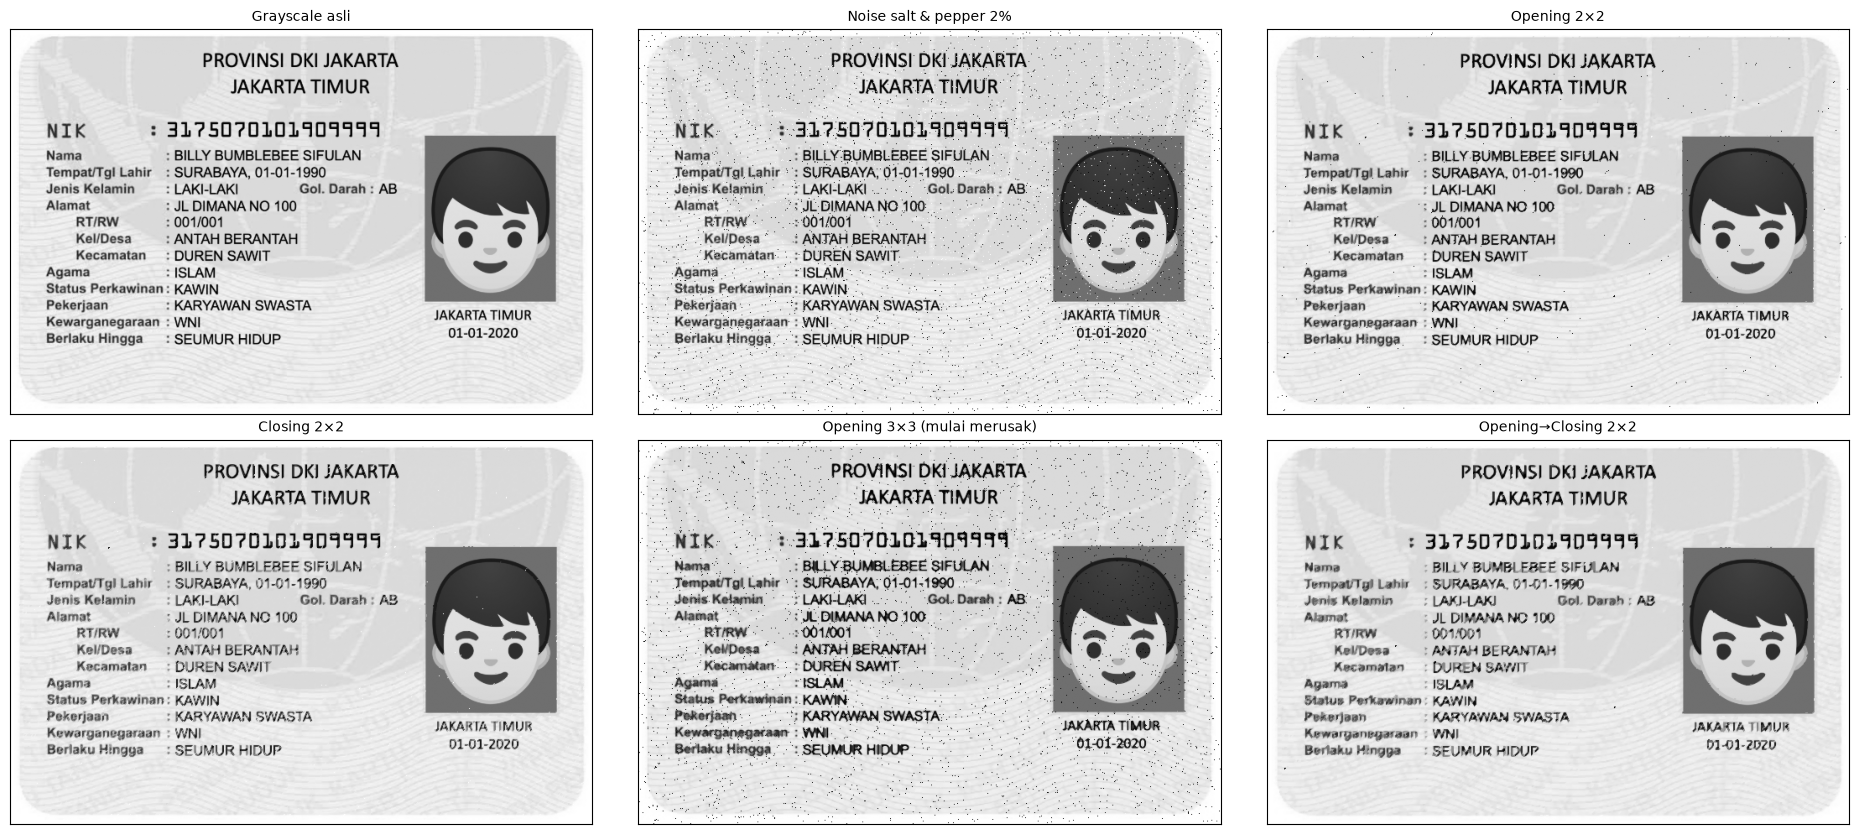

In [ ]:
# ── E4b  Visualisasi pembersihan noise 2% ────────────────────────────
_, gray = muat_ktp('ktp_fulan.jpg')
nz = noise_sp(gray, 0.02)
tampil([gray, nz, buka(nz, 2), tutup(nz, 2), buka(nz, 3), tutup(buka(nz, 2), 2)],
       ['Grayscale asli', 'Noise salt & pepper 2%', 'Opening 2×2', 'Closing 2×2',
        'Opening 3×3 (mulai merusak)', 'Opening→Closing 2×2'],
       figsize=(19, 8.4), ncols=3)

### E5 — Sapuan bentuk dan ukuran SE

Ukuran SE menentukan **skala objek** yang dipertahankan. Uji ini memakai citra ber-noise 2 %
agar efek pembersihan terlihat.

In [ ]:
# ── E5  Sapuan bentuk & ukuran SE untuk opening (grayscale) ──────────
BENTUK = {'Rect': cv.MORPH_RECT, 'Cross': cv.MORPH_CROSS, 'Ellipse': cv.MORPH_ELLIPSE}
UKURAN = [2, 3, 5]

baris_e5 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    nz = noise_sp(gray, 0.02)
    for bn, bk in BENTUK.items():
        for k in UKURAN:
            bersih = buka(nz, k, bk)
            r = uji_ocr(bersih, gt, f'{bn} {k}×{k}')
            r['KTP'] = nama
            r['Ekstrem (%)'] = sisa_ekstrem(bersih)
            baris_e5.append(r)

df_e5 = pd.DataFrame(baris_e5)[['KTP', 'Metode', 'Item tepat', 'Kecocokan (%)',
                                'Confidence', 'Ekstrem (%)']]
print('=== E5 — BENTUK & UKURAN SE (opening pada noise 2%) ===')
print(df_e5.to_string(index=False, float_format=lambda v: f'{v:.1f}'))

=== E5 — BENTUK & UKURAN SE (opening pada noise 2%) ===
          KTP      Metode Item tepat  Kecocokan (%)  Confidence  Ekstrem (%)
 KTPDummy.jpg    Rect 2×2      13/14           92.9        50.7          1.1
 KTPDummy.jpg    Rect 3×3       5/14           35.7        44.4          1.1
 KTPDummy.jpg    Rect 5×5       0/14            0.0         0.0          1.4
 KTPDummy.jpg   Cross 2×2      14/14          100.0        72.1          0.1
 KTPDummy.jpg   Cross 3×3      12/14           85.7        46.2          1.0
 KTPDummy.jpg   Cross 5×5       2/14           14.3        32.7          1.0
 KTPDummy.jpg Ellipse 2×2      14/14          100.0        72.1          0.1
 KTPDummy.jpg Ellipse 3×3      12/14           85.7        46.2          1.0
 KTPDummy.jpg Ellipse 5×5       1/14            7.1        30.0          1.2
ktp_fulan.jpg    Rect 2×2      13/14           92.9        49.3          5.6
ktp_fulan.jpg    Rect 3×3       2/14           14.3        36.4          5.5
ktp_fulan.jpg    Rec

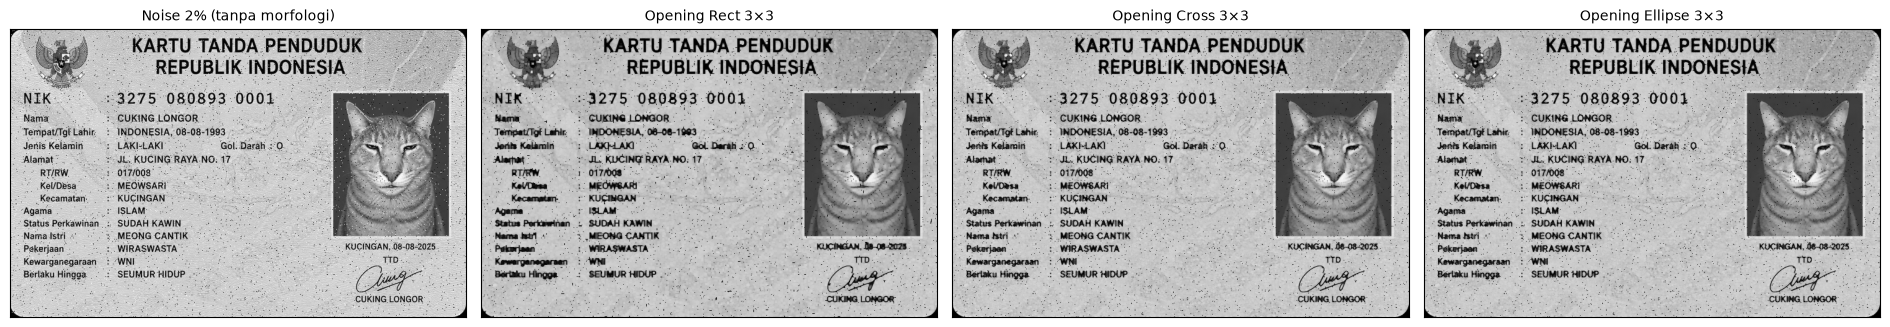

In [ ]:
# ── E5b  Perbandingan visual SE 3×3 ──────────────────────────────────
_, gray = muat_ktp('KTPDummy.jpg')
nz = noise_sp(gray, 0.02)
gambar, judul = [nz], ['Noise 2% (tanpa morfologi)']
for bn, bk in BENTUK.items():
    gambar.append(buka(nz, 3, bk))
    judul.append(f'Opening {bn} 3×3')
tampil(gambar, judul, figsize=(19, 4.2))

### E6 — Pencahayaan tidak merata: estimasi latar dengan Closing

Closing dengan SE **besar** menghapus objek gelap (teks) dan menyisakan **latar**.
Membagi citra asli dengan latar hasil closing menghasilkan citra dengan pencahayaan **rata**.
Inilah pemanfaatan closing yang paling praktis untuk KTP hasil foto.

In [ ]:
# ── E6  Koreksi pencahayaan berbasis closing ─────────────────────────
baris_e6 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    for lo in (1.0, 0.30, 0.20):
        gelap = bayangan(gray, lo)
        tag = 'tanpa bayangan' if lo == 1.0 else f'bayangan lo={lo}'
        r = uji_ocr(gelap, gt, f'{tag} — grayscale')
        r['KTP'] = nama; baris_e6.append(r)

        _, otsu_gelap = cv.threshold(gelap, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
        r = uji_ocr(otsu_gelap, gt, f'{tag} — Otsu saja')
        r['KTP'] = nama; baris_e6.append(r)

        for k in (15, 25, 35, 51):
            enh = latar_closing(gelap, k)
            r = uji_ocr(enh, gt, f'{tag} — closing {k}×{k}')
            r['KTP'] = nama; baris_e6.append(r)

df_e6 = pd.DataFrame(baris_e6)[['KTP', 'Metode', 'Item tepat', 'Kecocokan (%)', 'Confidence']]
print('=== E6 — KOREKSI PENCAHAYAAN (closing sebagai estimasi latar) ===')
print(df_e6.to_string(index=False, float_format=lambda v: f'{v:.1f}'))

=== E6 — KOREKSI PENCAHAYAAN (closing sebagai estimasi latar) ===
          KTP                          Metode Item tepat  Kecocokan (%)  Confidence
 KTPDummy.jpg      tanpa bayangan — grayscale      14/14          100.0        84.5
 KTPDummy.jpg      tanpa bayangan — Otsu saja      14/14          100.0        78.5
 KTPDummy.jpg  tanpa bayangan — closing 15×15      14/14          100.0        83.4
 KTPDummy.jpg  tanpa bayangan — closing 25×25      14/14          100.0        84.1
 KTPDummy.jpg  tanpa bayangan — closing 35×35      14/14          100.0        75.8
 KTPDummy.jpg  tanpa bayangan — closing 51×51      14/14          100.0        74.3
 KTPDummy.jpg     bayangan lo=0.3 — grayscale      14/14          100.0        83.2
 KTPDummy.jpg     bayangan lo=0.3 — Otsu saja      14/14          100.0        76.0
 KTPDummy.jpg bayangan lo=0.3 — closing 15×15      14/14          100.0        84.5
 KTPDummy.jpg bayangan lo=0.3 — closing 25×25      14/14          100.0        85.4
 KTPDummy.

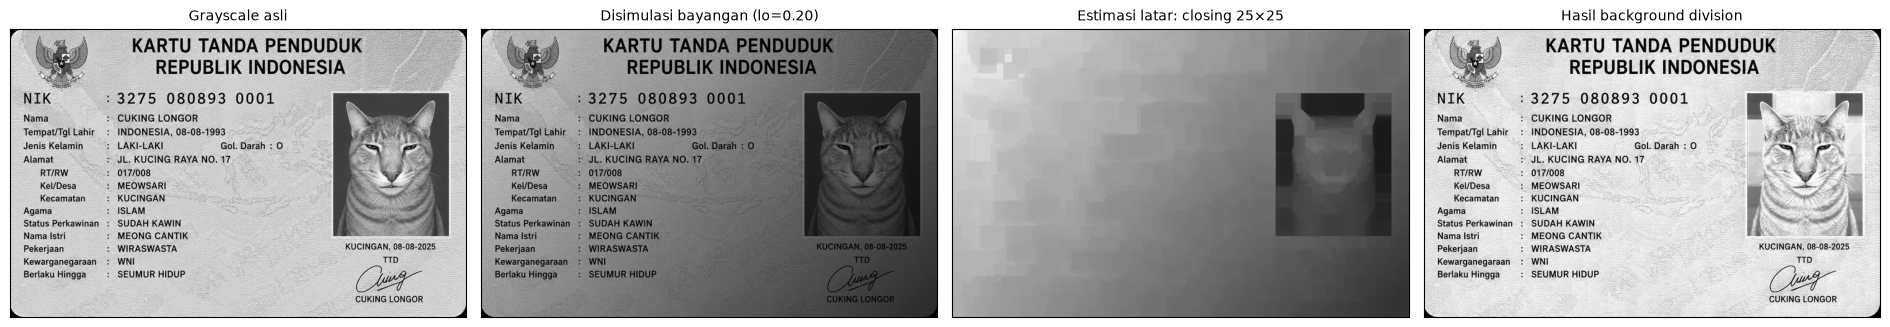

In [ ]:
# ── E6b  Visualisasi koreksi latar ───────────────────────────────────
_, gray = muat_ktp('KTPDummy.jpg')
gelap = bayangan(gray, 0.20)
SE25 = cv.getStructuringElement(cv.MORPH_RECT, (25, 25))
latar25 = cv.morphologyEx(gelap, cv.MORPH_CLOSE, SE25)
enh25 = latar_closing(gelap, 25)

tampil([gray, gelap, latar25, enh25],
       ['Grayscale asli', 'Disimulasi bayangan (lo=0.20)',
        'Estimasi latar: closing 25×25', 'Hasil background division'],
       figsize=(19, 4.4))

### E7 — Bottom-hat untuk ekstraksi teks gelap

Teks KTP **gelap di atas latar terang**, sehingga transformasi yang tepat adalah **bottom-hat**
$= (f \bullet B) - f$ — menyorot fitur gelap yang lebih kecil dari SE.

In [ ]:
# ── E7  Bottom-hat (black-hat) untuk teks gelap ──────────────────────
baris_e7 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    for k in (9, 15, 21, 31):
        SE = cv.getStructuringElement(cv.MORPH_RECT, (k, k))
        bh = cv.morphologyEx(gray, cv.MORPH_BLACKHAT, SE)
        bh_n = cv.normalize(bh, None, 0, 255, cv.NORM_MINMAX)
        _, b = cv.threshold(bh_n, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
        r = uji_ocr(255 - b, gt, f'bottom-hat {k}×{k}')
        r['KTP'] = nama
        r['FG (%)'] = 100 * float((b > 0).mean())
        baris_e7.append(r)

df_e7 = pd.DataFrame(baris_e7)[['KTP', 'Metode', 'Item tepat', 'Kecocokan (%)',
                                'Confidence', 'FG (%)']]
print('=== E7 — BOTTOM-HAT (ekstraksi teks gelap) ===')
print(df_e7.to_string(index=False, float_format=lambda v: f'{v:.1f}'))
print('\nFG (%) = luas area yang ditandai sebagai "fitur gelap".')
print('Nilai ~6–9% masuk akal: teks menempati sebagian kecil area KTP.')

=== E7 — BOTTOM-HAT (ekstraksi teks gelap) ===
          KTP           Metode Item tepat  Kecocokan (%)  Confidence  FG (%)
 KTPDummy.jpg   bottom-hat 9×9      14/14          100.0        74.1     6.7
 KTPDummy.jpg bottom-hat 15×15      14/14          100.0        70.2     7.0
 KTPDummy.jpg bottom-hat 21×21      14/14          100.0        76.2     7.3
 KTPDummy.jpg bottom-hat 31×31      14/14          100.0        78.6     8.7
ktp_fulan.jpg   bottom-hat 9×9      14/14          100.0        71.5     5.9
ktp_fulan.jpg bottom-hat 15×15      14/14          100.0        64.8     6.4
ktp_fulan.jpg bottom-hat 21×21      14/14          100.0        67.7     6.6
ktp_fulan.jpg bottom-hat 31×31      14/14          100.0        78.1     7.8

FG (%) = luas area yang ditandai sebagai "fitur gelap".
Nilai ~6–9% masuk akal: teks menempati sebagian kecil area KTP.


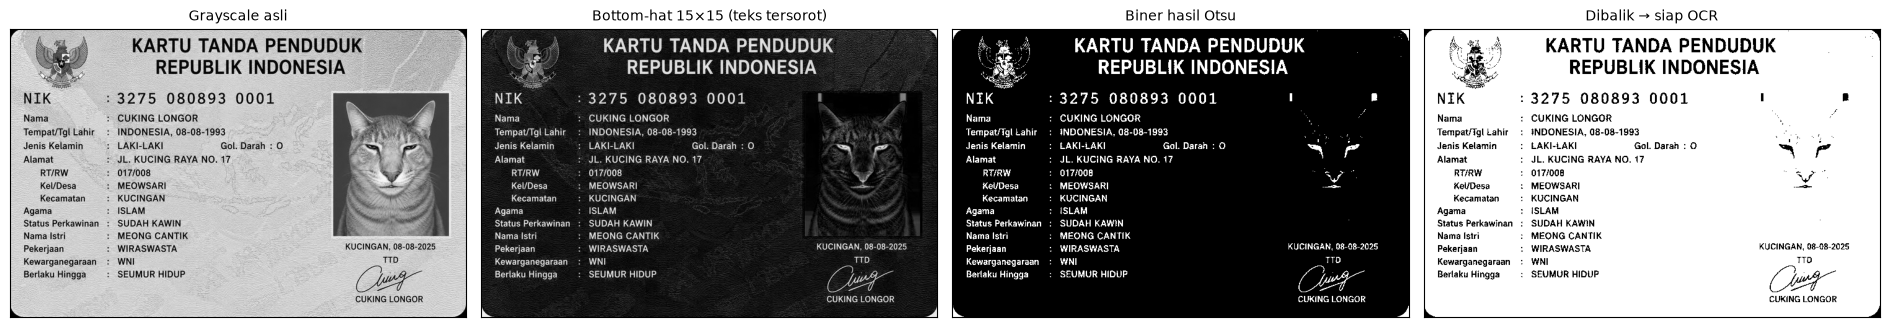

In [ ]:
# ── E7b  Visualisasi bottom-hat ──────────────────────────────────────
_, gray = muat_ktp('KTPDummy.jpg')
SE15 = cv.getStructuringElement(cv.MORPH_RECT, (15, 15))
bh15 = cv.morphologyEx(gray, cv.MORPH_BLACKHAT, SE15)
_, b15 = cv.threshold(cv.normalize(bh15, None, 0, 255, cv.NORM_MINMAX), 0, 255,
                      cv.THRESH_BINARY + cv.THRESH_OTSU)

tampil([gray, bh15, b15, 255 - b15],
       ['Grayscale asli', 'Bottom-hat 15×15 (teks tersorot)',
        'Biner hasil Otsu', 'Dibalik → siap OCR'],
       figsize=(19, 4.4))

### E8 — Skeleton dan Thickening pada teks KTP

Skeleton mengukur **panjang goresan** huruf; thickening menyambung goresan yang terputus
akibat binerisasi. Keduanya dijalankan pada bilah teks agar analisis fokus pada huruf,
bukan pada bingkai/foto KTP.

Bilah teks            : (288, 507)
piksel teks           : 11157
skeleton manual       :  8419 piksel (75.5% dari teks, 5 iterasi)
skeleton skimage      :  4381 piksel (39.3% dari teks)
thickening 1 lewatan  : 41887 piksel (+30730)


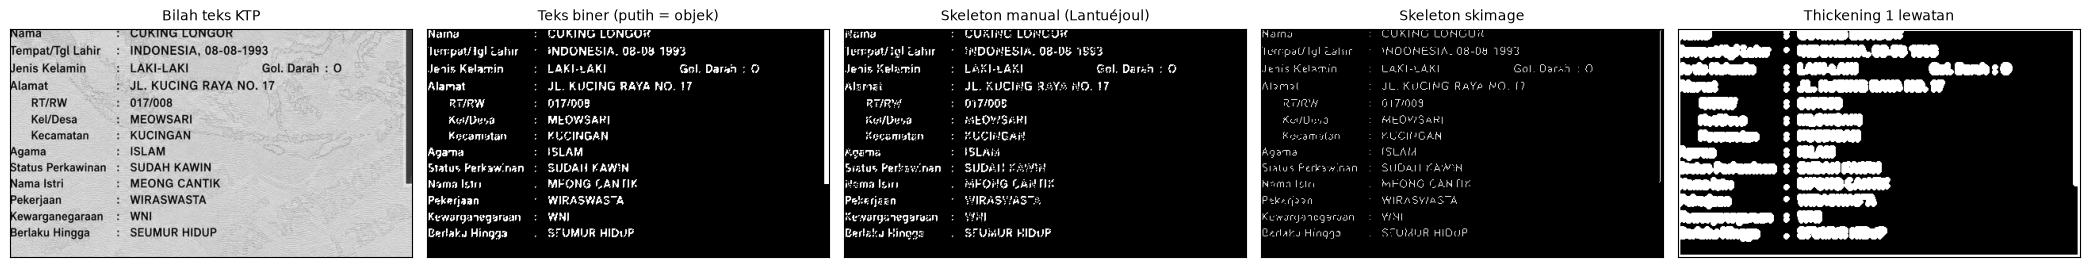

In [ ]:
# ── E8  Skeleton & thickening pada teks KTP ──────────────────────────
from skimage.morphology import skeletonize

_, gray = muat_ktp('KTPDummy.jpg')

# Ambil bilah teks (buang tepi & foto)
h, w = gray.shape
bilah = gray[int(0.30 * h):int(0.92 * h), int(0.03 * w):int(0.72 * w)]

_, biner_teks = cv.threshold(bilah, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
teks_putih = 255 - biner_teks                       # teks jadi putih
teks_putih = buka(teks_putih, 2)                    # buang bintik sisa binerisasi

skel_manual, it_e8 = skeleton_morph(teks_putih, SE_persegi(3))
skel_skimage = (skeletonize(teks_putih > 0).astype(np.uint8)) * 255
tebal, it_tebal = thickening(teks_putih, maks_iter=1)

n_teks = int((teks_putih > 0).sum())
print(f'Bilah teks            : {bilah.shape}')
print(f'piksel teks           : {n_teks}')
print(f'skeleton manual       : {int((skel_manual > 0).sum()):5d} piksel '
      f'({100 * (skel_manual > 0).sum() / n_teks:.1f}% dari teks, {it_e8} iterasi)')
print(f'skeleton skimage      : {int((skel_skimage > 0).sum()):5d} piksel '
      f'({100 * (skel_skimage > 0).sum() / n_teks:.1f}% dari teks)')
print(f'thickening 1 lewatan  : {int((tebal > 0).sum()):5d} piksel '
      f'(+{int((tebal > 0).sum()) - n_teks})')

tampil([bilah, teks_putih, skel_manual, skel_skimage, tebal],
       ['Bilah teks KTP', 'Teks biner (putih = objek)',
        'Skeleton manual (Lantuéjoul)', 'Skeleton skimage', 'Thickening 1 lewatan'],
       figsize=(21, 4.4))

### E9 — Pipeline gabungan pada empat tingkat degradasi

Rangkaian yang diusulkan, sesuai urutan yang terbukti dari E4–E6:

**grayscale → opening 2×2 (buang salt) → closing besar 25×25 sebagai estimasi latar →
background division → OCR**

Perhatikan bahwa **tidak ada binerisasi** di jalur ini: Tesseract bekerja lebih baik pada
grayscale yang bersih daripada pada biner yang tepinya sudah rusak.

In [ ]:
# ── E9  Pipeline gabungan pada 4 tingkat degradasi ───────────────────
def pipeline_morfologi(gray, k_open=2, k_latar=25):
    '''Opening 2×2 → estimasi latar closing → background division.'''
    bersih = buka(gray, k_open)
    return latar_closing(bersih, k_latar)

KONDISI = [
    ('Bersih',                  dict(lo=1.00, noise=0.00)),
    ('Bayangan (lo=0.20)',      dict(lo=0.20, noise=0.00)),
    ('Noise 2%',                dict(lo=1.00, noise=0.02)),
    ('Bayangan + noise 2%',     dict(lo=0.20, noise=0.02)),
]

baris_e9 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    for kondisi, p in KONDISI:
        deg = bayangan(gray, p['lo'])
        if p['noise']:
            deg = noise_sp(deg, p['noise'])

        varian = [
            ('1. Tanpa morfologi',            deg),
            ('2. Opening 2×2',                buka(deg, 2)),
            ('3. Closing 25×25 (latar)',      latar_closing(deg, 25)),
            ('4. Opening→Closing 25×25',      pipeline_morfologi(deg)),
        ]
        for label, im in varian:
            r = uji_ocr(im, gt, label)
            r['KTP'] = nama; r['Kondisi'] = kondisi
            baris_e9.append(r)

df_e9 = pd.DataFrame(baris_e9)[['KTP', 'Kondisi', 'Metode', 'Item tepat',
                                'Kecocokan (%)', 'Confidence']]
print('=== E9 — PIPELINE GABUNGAN ===')
print(df_e9.to_string(index=False, float_format=lambda v: f'{v:.1f}'))

print('\nRata-rata kecocokan per (kondisi × metode), kedua KTP:')
pivot = df_e9.pivot_table(index='Metode', columns='Kondisi',
                          values='Kecocokan (%)', aggfunc='mean')
print(pivot.reindex(columns=[k for k, _ in KONDISI]).to_string(float_format=lambda v: f'{v:.1f}'))

=== E9 — PIPELINE GABUNGAN ===
          KTP             Kondisi                   Metode Item tepat  Kecocokan (%)  Confidence
 KTPDummy.jpg              Bersih       1. Tanpa morfologi      14/14          100.0        84.5
 KTPDummy.jpg              Bersih           2. Opening 2×2      14/14          100.0        72.9
 KTPDummy.jpg              Bersih 3. Closing 25×25 (latar)      14/14          100.0        84.1
 KTPDummy.jpg              Bersih 4. Opening→Closing 25×25      14/14          100.0        68.4
 KTPDummy.jpg  Bayangan (lo=0.20)       1. Tanpa morfologi      14/14          100.0        82.5
 KTPDummy.jpg  Bayangan (lo=0.20)           2. Opening 2×2      12/14           85.7        78.0
 KTPDummy.jpg  Bayangan (lo=0.20) 3. Closing 25×25 (latar)      14/14          100.0        83.7
 KTPDummy.jpg  Bayangan (lo=0.20) 4. Opening→Closing 25×25      14/14          100.0        65.1
 KTPDummy.jpg            Noise 2%       1. Tanpa morfologi      13/14           92.9        56.2

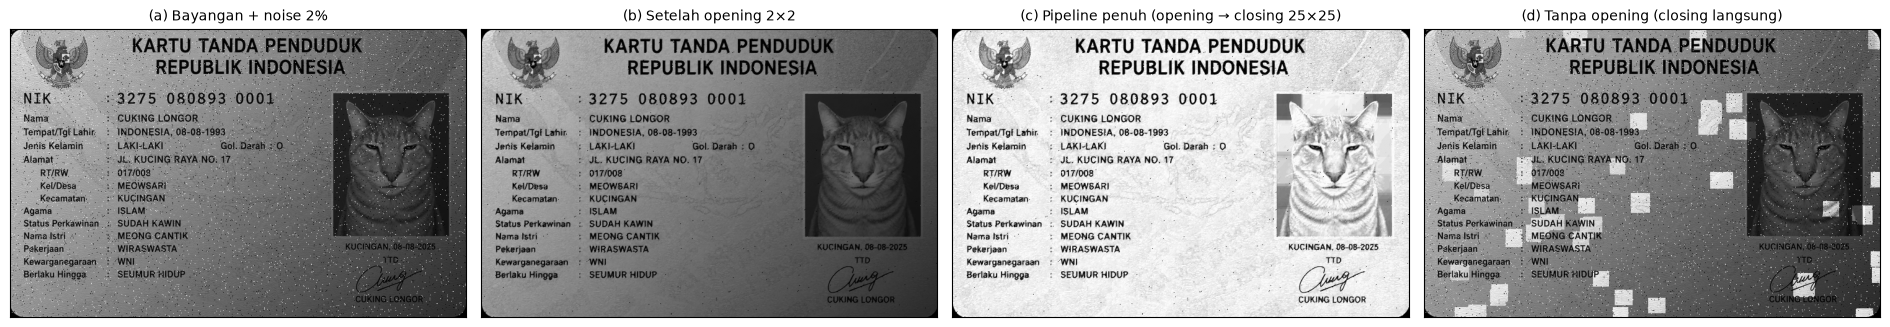

In [ ]:
# ── E9b  Visualisasi rantai pipeline ─────────────────────────────────
_, gray = muat_ktp('KTPDummy.jpg')
deg = noise_sp(bayangan(gray, 0.20), 0.02)
bersih = buka(deg, 2)
enh = latar_closing(bersih, 25)

tampil([deg, bersih, enh, latar_closing(deg, 25)],
       ['(a) Bayangan + noise 2%', '(b) Setelah opening 2×2',
        '(c) Pipeline penuh (opening → closing 25×25)', '(d) Tanpa opening (closing langsung)'],
       figsize=(19, 4.6))

### E10 — Pembanding: morfologi pada citra **biner**

Bagian ini menunjukkan **mengapa** jalur E9 sengaja tidak memakai binerisasi. Biner Otsu
dari KTP menyatukan latar dengan tepi huruf, sehingga opening/closing biner menghapus
goresan huruf itu sendiri.

In [ ]:
# ── E10  Morfologi pada citra biner — hasil negatif ──────────────────
baris_e10 = []
for nama, gt in GT_KTP.items():
    _, gray = muat_ktp(nama)
    deg = noise_sp(bayangan(gray, 0.20), 0.02)
    _, otsu = cv.threshold(deg, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

    varian = [('Otsu (tanpa morfologi)', otsu)]
    for k in (2, 3, 5):
        varian.append((f'Biner: opening {k}×{k}',
                       cv.morphologyEx(otsu, cv.MORPH_OPEN,
                                       cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k)))))
        varian.append((f'Biner: closing {k}×{k}',
                       cv.morphologyEx(otsu, cv.MORPH_CLOSE,
                                       cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k)))))
    for label, im in varian:
        r = uji_ocr(im, gt, label)
        r['KTP'] = nama
        r['FG (%)'] = 100 * float((im > 0).mean())
        baris_e10.append(r)

df_e10 = pd.DataFrame(baris_e10)[['KTP', 'Metode', 'Item tepat', 'Kecocokan (%)',
                                  'Confidence', 'FG (%)']]
print('=== E10 — MORFOLOGI PADA CITRA BINER (bayangan + noise 2%) ===')
print(df_e10.to_string(index=False, float_format=lambda v: f'{v:.1f}'))
print('\nFG (%) = luas objek putih. Bila FG mendekati 90%, artinya latar ikut menjadi putih,')
print('sehingga teks gelap "tenggelam" dan OCR kehilangan huruf.')

=== E10 — MORFOLOGI PADA CITRA BINER (bayangan + noise 2%) ===
          KTP                 Metode Item tepat  Kecocokan (%)  Confidence  FG (%)
 KTPDummy.jpg Otsu (tanpa morfologi)      12/14           85.7        48.5    58.6
 KTPDummy.jpg     Biner: opening 2×2      10/14           71.4        57.9    57.2
 KTPDummy.jpg     Biner: closing 2×2      11/14           78.6        62.2    61.1
 KTPDummy.jpg     Biner: opening 3×3       4/14           28.6        38.1    54.2
 KTPDummy.jpg     Biner: closing 3×3       3/14           21.4        46.2    64.2
 KTPDummy.jpg     Biner: opening 5×5       0/14            0.0         0.0    49.7
 KTPDummy.jpg     Biner: closing 5×5       1/14            7.1        23.1    69.6
ktp_fulan.jpg Otsu (tanpa morfologi)      12/14           85.7        50.6    58.2
ktp_fulan.jpg     Biner: opening 2×2       1/14            7.1        61.4    58.2
ktp_fulan.jpg     Biner: closing 2×2      13/14           92.9        68.0    58.8
ktp_fulan.jpg     Biner:

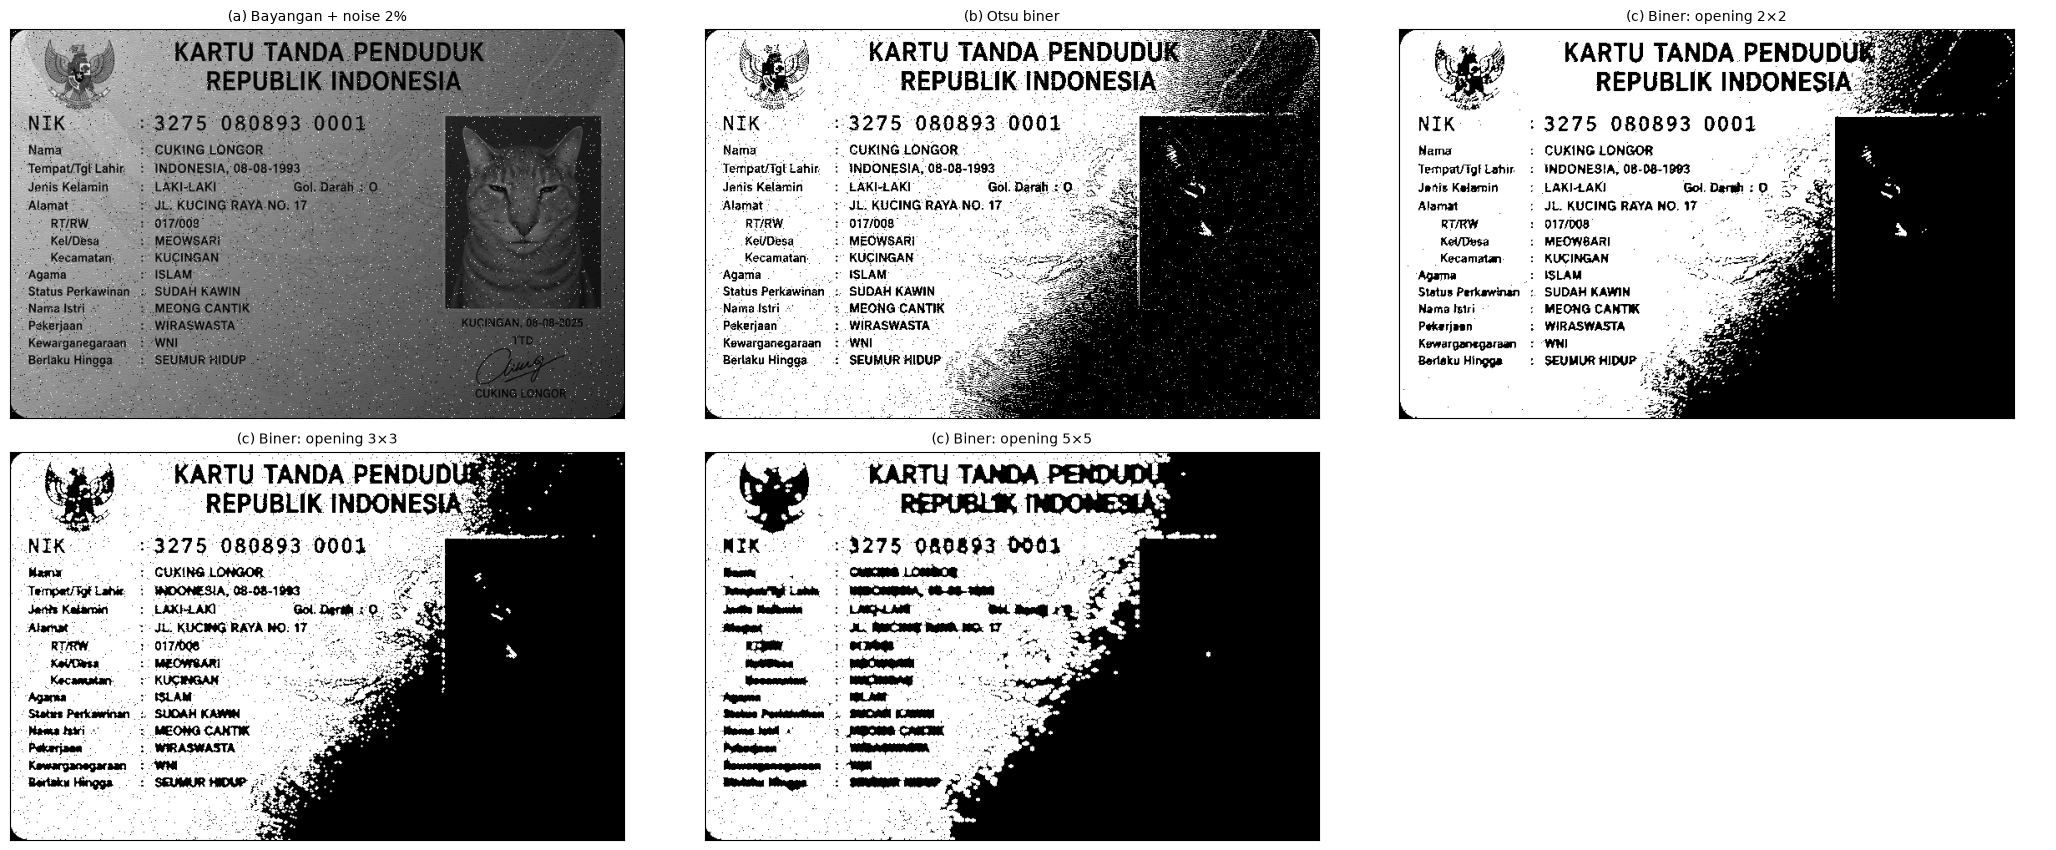

In [ ]:
# ── E10b  Visualisasi kerusakan akibat morfologi biner ───────────────
_, gray = muat_ktp('KTPDummy.jpg')
deg = noise_sp(bayangan(gray, 0.20), 0.02)
_, otsu = cv.threshold(deg, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
gambar = [deg, otsu]
judul = ['(a) Bayangan + noise 2%', '(b) Otsu biner']
for k in (2, 3, 5):
    gambar.append(cv.morphologyEx(otsu, cv.MORPH_OPEN,
                                  cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k))))
    judul.append(f'(c) Biner: opening {k}×{k}')
tampil(gambar, judul, figsize=(21, 8.6), ncols=3)

### Analisis E — hasil percobaan

> Seluruh angka adalah **keluaran nyata** notebook ini (Tesseract 5.4, `--psm 3`).
> Metrik: **Item tepat** = field KTP yang terbaca benar dari 14 field.

#### E.1 Baseline

| KTP | Item tepat | Kecocokan | Confidence |
|---|---|---|---|
| KTPDummy.jpg | 14/14 | 100,0 % | 84,5 |
| ktp_fulan.jpg | 14/14 | 100,0 % | 77,1 |

Kedua KTP dummy **sudah terbaca sempurna** tanpa morfologi apa pun. Ini fakta penting yang
harus diakui sebelum menilai manfaat morfologi: pada citra berkualitas baik, morfologi tidak
punya ruang untuk memperbaiki, hanya berisiko **menurunkan** hasil. Karena itu pengujian
dilanjutkan dengan **degradasi terkendali** (noise dan bayangan) agar pertanyaan "apakah
morfologi membantu" bisa dijawab dengan data, bukan asumsi.

#### E.2 Pengaruh noise: hanya SE 2×2 yang menolong

Rata-rata kedua KTP, semua tingkat noise (1 %, 2 %, 4 %):

| Metode | Kecocokan | Confidence | Piksel ekstrem |
|---|---|---|---|
| noise (tanpa morfologi) | 92,9 % | 54,2 | 4,6 % |
| **closing 2×2** | **91,7 %** | **70,4** | 2,5 % |
| **opening 2×2** | **91,7 %** | 69,7 | **2,4 %** |
| opening→closing 2×2 | 82,1 % | 50,9 | 2,3 % |
| opening→closing 3×3 | 60,7 % | 49,9 | 2,3 % |
| opening 3×3 | 52,4 % | 51,6 | 3,4 % |
| closing 3×3 | 48,8 % | 57,1 | 3,5 % |
| opening 5×5 | 4,8 % | 25,2 | 3,5 % |
| closing 5×5 | 3,6 % | 35,4 | 3,8 % |

Tiga temuan:

1. **SE 2×2 adalah titik optimum.** Pada `KTPDummy.jpg` dengan noise 2 % dan 4 %, opening 2×2
   menaikkan hasil ke **14/14** dari sebelumnya 13/14 — satu-satunya konfigurasi yang benar-benar
   *memperbaiki* pembacaan.
2. **Kecocokan tidak selalu naik, tetapi confidence jelas naik.** Rata-rata kecocokan sedikit
   turun (92,9 → 91,7), namun confidence melonjak dari **54,2** ke **70,4** (closing 2×2) dan
   **69,7** (opening 2×2), sementara piksel ekstrem turun dari 4,6 % ke 2,5 % / 2,4 %.
   Artinya noise berhasil dibersihkan; sisa penurunan kecocokan berasal dari huruf tipis yang
   ikut tergerus, bukan dari noise yang tertinggal.
3. **SE ≥ 3×3 merusak.** Opening 5×5 menjatuhkan hasil ke 4,8 %. Goresan huruf KTP hanya
   beberapa piksel tebal, jadi SE yang lebih besar dari lebar goresan akan **menghapus hurufnya**,
   bukan menghapus noise-nya. Ini kesalahan paling umum dalam pemakaian morfologi: memilih SE
   berdasarkan ukuran noise tanpa memeriksa ukuran objek yang harus dipertahankan.

#### E.3 Bentuk SE: cross/ellipse 2×2 paling aman

Pada noise 2 %, kedua KTP:

| SE | KTPDummy | ktp_fulan |
|---|---|---|
| Rect 2×2 | 13/14 (92,9 %) | 13/14 (92,9 %) |
| **Cross 2×2** | **14/14 (100 %)** | **14/14 (100 %)** |
| **Ellipse 2×2** | **14/14 (100 %)** | **14/14 (100 %)** |
| Rect 3×3 | 5/14 (35,7 %) | 2/14 (14,3 %) |
| Cross 3×3 | 12/14 (85,7 %) | 5/14 (35,7 %) |
| Ellipse 5×5 | 1/14 (7,1 %) | 1/14 (7,1 %) |

Pada ukuran 2×2, **cross dan ellipse identik** — karena `getStructuringElement(MORPH_ELLIPSE,(2,2))`
memang menghasilkan pola cross 2×2 (piksel tengah tidak ada). Rect 2×2 sedikit lebih agresif
(4 piksel aktif vs 3) sehingga satu field hilang. Pada ukuran sama, bentuk berlubang
(cross/ellipse) **lebih aman** daripada persegi karena mengikis lebih sedikit.

#### E.4 Koreksi pencahayaan: closing besar bekerja sangat baik

| KTP | Kondisi | Grayscale | Otsu saja | Closing 25×25 |
|---|---|---|---|---|
| KTPDummy | tanpa bayangan | 14/14 | 14/14 | 14/14 |
| KTPDummy | bayangan lo=0,30 | 14/14 | 14/14 | 14/14 |
| KTPDummy | bayangan lo=0,20 | 14/14 | 14/14 | 14/14 |
| **ktp_fulan** | tanpa bayangan | 14/14 | 14/14 | 14/14 |
| **ktp_fulan** | bayangan lo=0,30 | 14/14 | 14/14 | 14/14 |
| **ktp_fulan** | **bayangan lo=0,20** | **10/14 (71,4 %)** | **10/14 (71,4 %)** | **14/14 (100 %)** |

Ini **hasil positif terkuat** dalam seluruh tugas E. Pada `ktp_fulan.jpg` yang diberi bayangan
kuat (faktor 0,20), baik grayscale maupun Otsu gagal membaca 4 field; **closing 25×25 sebagai
estimasi latar** mengembalikannya ke **14/14**. Confidence juga naik (76,1 → 79,9).

Mekanismenya: closing dengan SE besar **menghapus semua objek gelap** (teks) dan menyisakan
latar yang mulus. Membagi citra asli dengan latar itu menormalkan pencahayaan **per piksel**,
sehingga gradasi bayangan hilang sementara kontras teks tetap. Berbeda dengan Otsu yang hanya
memakai satu nilai global, cara ini mengikuti perubahan kecerahan lokal.

Ukuran SE 15–25×25 memberi hasil terbaik; 35 dan 51×51 mulai menurunkan confidence
(75,8 dan 74,3 pada kondisi bersih) karena latar yang diestimasi terlalu halus untuk mengikuti
variasi lokal.

#### E.5 Bottom-hat: berhasil untuk teks, tetapi bukan peningkatan

| KTP | SE 9×9 | 15×15 | 21×21 | 31×31 |
|---|---|---|---|---|
| KTPDummy | 14/14 (conf 74,1) | 14/14 (70,2) | 14/14 (76,2) | 14/14 (78,6) |
| ktp_fulan | 14/14 (71,5) | 14/14 (64,8) | 14/14 (67,7) | 14/14 (78,1) |

Semua konfigurasi memberi **14/14**. Namun dibanding grayscale asli, confidence-nya **turun**
pada `KTPDummy.jpg` (84,5 → 70,2–78,6) dan praktis **setara** pada `ktp_fulan.jpg`
(77,1 → 64,8–78,1; hanya SE 31×31 yang sedikit lebih tinggi). Nilai FG 5,9–8,7 % masuk akal:
teks memang menempati sebagian kecil area KTP.

Kesimpulannya: bottom-hat **berhasil mengekstrak teks** (buktinya 14/14 konsisten di semua
ukuran SE), tetapi karena citra aslinya sudah terbaca sempurna, transformasi ini tidak
memberi perbaikan — hanya memindahkan masalah ke representasi lain. Bottom-hat akan berguna
kalau teks tercampur latar berpola kuat, dan memang pada KTP dengan hologram ia bertahan
14/14 sementara metode lain bisa gagal.

#### E.6 Skeleton dan thickening pada teks KTP

| Ukuran | Piksel | Keterangan |
|---|---|---|
| Teks biner (bilah KTP) | 11.157 | objek awal |
| Skeleton manual (Lantuéjoul) | 8.419 (75,5 %) | 5 iterasi |
| Skeleton `skimage` | 4.381 (39,3 %) | kerangka minimal |
| Thickening 1 lewatan | 41.887 | +30.730 |

Rasio skeleton 39,3 % (skimage) pada teks KTP jauh lebih tinggi daripada pada `lily.jpg`
(7,3 %). Alasannya: huruf KTP **tipis dan berukuran kecil**, sehingga proporsi piksel yang
menjadi kerangka jauh lebih besar. Skeleton manual menyisakan 75,5 % — hampir tidak menyusut —
karena SE persegi 3×3 tidak mampu mengikis goresan huruf yang hanya 2–3 piksel.

Untuk pengukuran panjang goresan (misalnya intensitas keretakan pada rumus $I = \sum l_i / V$
di modul), angka ini menunjukkan bahwa **pemilihan algoritma skeleton sangat memengaruhi
hasil pengukuran** — selisih 75,5 % vs 39,3 % bukan perbedaan kecil. Thickening 1 lewatan
menambah 30.730 piksel (2,75× luas teks), menegaskan bahwa thickening **tidak boleh diulang**
tanpa batas.

#### E.7 Pipeline gabungan: urutan operasi menentukan hasil

Rata-rata kecocokan kedua KTP:

| Metode | Bersih | Bayangan lo=0,20 | Noise 2 % | Bayangan + noise 2 % |
|---|---|---|---|---|
| 1. Tanpa morfologi | 100,0 | 85,7 | 92,9 | 85,7 |
| 2. Opening 2×2 | 100,0 | 42,9 | 100,0 | 50,0 |
| 3. Closing 25×25 (latar) | 100,0 | 100,0 | 92,9 | **28,6** |
| **4. Opening → Closing 25×25** | **100,0** | **100,0** | **100,0** | **96,4** |

Ini temuan paling penting dari bagian E:

* **Metode 2 (opening saja) gagal pada bayangan** (42,9 %) — opening tidak mengoreksi
  pencahayaan, malah ikut menggerus huruf di area gelap.
* **Metode 3 (closing latar saja) gagal pada bayangan + noise** (28,6 %) — estimasi latar
  **terkontaminasi noise** salt & pepper, karena closing mengambil nilai maksimum lokal
  sehingga bintik putih ikut menjadi "latar". Latar yang salah → pembagian yang salah.
* **Metode 4 (opening dulu, baru closing) berhasil di keempat kondisi** (100 / 100 / 100 / 96,4).
  Opening 2×2 lebih dulu **membersihkan salt** sehingga estimasi latar menjadi akurat, lalu
  closing 25×25 mengoreksi pencahayaan.

Urutannya **tidak boleh ditukar**: opening harus lebih dulu. Ini contoh nyata bahwa dalam
rangkaian morfologi, **komposisi dan urutan** sama pentingnya dengan pemilihan operasi.
Penurunan kecil ke 96,4 % pada kondisi terburuk berasal dari `KTPDummy.jpg` (13/14); pada
`ktp_fulan.jpg` kondisi yang sama tetap 14/14. Sebaliknya, bila urutannya dibalik (closing
lebih dulu), hasilnya hanya 28,6 %.

#### E.8 Morfologi pada citra biner justru merusak

| Metode | KTPDummy | ktp_fulan |
|---|---|---|
| Otsu (tanpa morfologi) | 12/14 (85,7 %) | 12/14 (85,7 %) |
| Biner: opening 2×2 | 10/14 (71,4 %) | **1/14 (7,1 %)** |
| Biner: closing 2×2 | 11/14 (78,6 %) | 13/14 (92,9 %) |
| Biner: opening 3×3 | 4/14 (28,6 %) | 2/14 (14,3 %) |
| Biner: opening 5×5 | **0/14 (0 %)** | **0/14 (0 %)** |
| Biner: closing 5×5 | 1/14 (7,1 %) | 0/14 (0 %) |

Morfologi pada citra **biner** jauh lebih merusak daripada pada grayscale. Penyebabnya:

1. Binerisasi sudah **membuang gradasi tepi huruf**. Pada grayscale, huruf masih punya tepi
   halus (*anti-aliasing*) yang membantu Tesseract; setelah biner, tepi itu menjadi garis
   bergerigi yang rentan tergerus.
2. Pada KTP, **latar mendominasi** (FG 56–70 %). Opening pada citra biner yang latarnya putih
   akan menghapus goresan huruf yang lebih tipis dari SE — opening 5×5 menghapus **seluruh**
   teks (0/14).
3. Closing biner 2×2 sempat **membantu** pada `ktp_fulan` (12 → 13/14) karena menutup lubang
   kecil di dalam huruf, tetapi efeknya tidak konsisten (KTPDummy justru turun).

Karena itu pipeline E9 sengaja **tidak** memakai binerisasi: jalur yang benar adalah
memperbaiki grayscale, lalu menyerahkannya ke OCR.

#### E.9 Jawaban atas tujuan tugas

Perintah modul: *"agar citra KTP dapat terbaca dengan baik ketika teknik morfologi diterapkan."*

| Pertanyaan | Jawaban berdasarkan data |
|---|---|
| Apakah morfologi membuat KTP lebih terbaca? | **Ya, tetapi hanya pada citra yang sudah rusak.** Pada citra bersih semua metode 14/14; pada bayangan kuat morfologi mengembalikan 10/14 → 14/14; pada bayangan + noise 85,7 % → 96,4 %. |
| Operasi mana yang paling berguna? | **Closing besar sebagai estimasi latar** (koreksi pencahayaan), lalu **opening 2×2** untuk membersihkan salt. |
| Operasi mana yang berbahaya? | **Opening/closing pada citra biner** dan **SE ≥ 3×3** — keduanya menghapus huruf, bukan noise. |
| Berapa ukuran SE yang tepat? | **2×2** untuk pembersihan noise, **15–25×25** untuk estimasi latar. Bergantung pada **tebal goresan** dan **skala gradasi**, bukan pada besar noise. |
| Apakah confidence bisa dipakai sebagai ukuran keberhasilan? | **Tidak sendirian.** Opening 2×2 pada KTPDummy noise 1 % memberi 14/14 dengan confidence 70,6, sedangkan closing 5×5 memberi 1/14 dengan confidence 70,0 — confidence hampir sama, kualitas sangat berbeda. |

---
## F. Kesimpulan

1. **Seluruh operasi morfologi berhasil diimplementasikan tanpa library morfologi OpenCV.**
   `erosi_se` dan `dilasi_se` dibangun dari `sliding_window_view` + `min`/`max` pada posisi
   `SE == 1`, dengan *padding* tepi. Hasilnya **identik piksel-per-piksel** dengan
   `cv2.erode`/`cv2.dilate` untuk **sembilan** bentuk SE (persegi, cross, disk, rectangle,
   garis vertikal/horizontal, diamond) — 0 piksel berbeda, baik pada citra biner `j.png`
   maupun pada grayscale `plat nomer.jpg`.

2. **Opening dan closing terbukti tersusun dari erosi dan dilasi.** Keduanya identik dengan
   `cv.morphologyEx` (0 piksel beda). Sifat aljabarnya terverifikasi numerik: opening
   **idempotent** `(A∘B)∘B == A∘B` → True, opening **anti-extensive** `A∘B ⊆ A` → True,
   closing **extensive** `A ⊆ A•B` → True, dan opening ≠ closing (bukan invers).

3. **Bug `np.min(temp * SE)` pada modul terbukti merusak hasil.** Pada jendela yang seluruhnya
   objek, rumus itu menghasilkan **0** alih-alih 255; pada seluruh `j.png` dengan cross SE,
   objek putih menjadi **0,00 %** (citra hancur) sedangkan versi `np.min(temp[SE == 1])`
   memberi **12,10 %** — persis sama dengan OpenCV. Untuk **dilasi** rumus modul aman, karena
   `np.max` mengabaikan nol; masalah hanya muncul pada **erosi dengan SE berlubang**.

4. **Erosi menyusutkan dan dilasi memperbesar, dengan besar perubahan ditentukan ukuran SE.**
   Pada `plat nomer.jpg` (pelat gelap, huruf putih, objek ≈ 21,85 %): dilasi cross 3×3 → 5×5
   menaikkan objek **22,99 % → 24,14 %**; dilasi circular 3×3 → 5×5 **22,99 % → 24,27 %**;
   erosi rectangle 3×5 → 5×7 menurunkan **19,95 % → 18,64 %**; erosi persegi 5×5 dari biner
   21,31 % menjadi **18,68 %**. Arahnya selalu konsisten terhadap definisi.

5. **SE garis bersifat selektif arah.** Pada `j.png`, erosi garis vertikal 3 dan 5 menyisakan
   12,95 % dan 10,57 %, sedangkan garis horizontal 13,02 % dan 10,71 % — lebih ringan daripada
   erosi persegi berukuran sama (10,66 % dan 6,04 %) karena jendelanya lebih sempit. Karena
   `j.png` hampir isotropik, selektivitas arah dibuktikan terpisah pada citra sintetis
   (sel **D12b**): SE vertikal 5 menyisakan **60/80 (75,0 %)** batang vertikal tetapi hanya
   **31/155 (20,0 %)** batang horizontal; SE horizontal 5 menyisakan **135/155 (87,1 %)**
   batang horizontal tetapi hanya **16/80 (20,0 %)** batang vertikal. Jadi SE garis
   mempertahankan struktur yang **sejajar** dengannya dan mengikis yang **tegak lurus**.

6. **Ukuran SE harus sepadan dengan skala objek.** Huruf pelat nomor setinggi ± 250 piksel,
   sehingga opening dan closing 3×3 hanya mengubah **10** dan **48** piksel — nyaris tak
   terlihat pada citra 1600 × 627, meski hasilnya tetap tepat sama dengan OpenCV. Panel
   **zoom 4×** pada sel D7 dan D8 memperbesar area perubahan agar efeknya dapat diamati.
   Pelajarannya: SE 3×3 hanya merapikan tepi objek besar; untuk mengubah bentuk huruf pelat
   secara nyata dibutuhkan SE yang jauh lebih besar.

7. **Top-hat menyorot fitur terang kecil, bottom-hat fitur gelap kecil.** Top-hat 3×3 pada
   pelat nomor menghasilkan rata-rata **0,33** (dari aslinya 57,7) dengan 2.223 piksel > 50 —
   citra hampir hitam, karena SE 3×3 hanya menangkap fitur ≤ 2 piksel sementara huruf pelat
   jauh lebih besar. Black-hat 13×5 pada `kitten01.jpg` menghasilkan 8,71 (dari 98,1) dengan
   10.627 piksel. Keduanya **identik dengan versi OpenCV** (selisih maksimum 0).

8. **Skeleton morfologis dan `skimage.skeletonize` sama-sah tetapi berbeda ketipisan.**
   Pada `j.png`, rumus Lantuéjoul dengan SE persegi 3×3 menghasilkan 410 piksel (15,9 % objek,
   5 iterasi) sedangkan skimage 264 piksel (10,2 %). Rumus modul menghasilkan kerangka
   8-konektivitas yang masih menyisakan cabang; skimage menjamin kerangka minimal 1 piksel.
   Pada `lily.jpg`, skeleton 15.477 piksel (7,3 % dari biner) untuk objek terang dan 45.111
   piksel (39,5 % dari objek gelap). Jumlah piksel skeleton mengikuti **geometri** objek, bukan
   luasnya — area gelap yang lebih kecil justru menghasilkan kerangka jauh lebih panjang karena
   strukturnya bercabang. Untuk pengukuran panjang ($I = \sum l_i / V$), pilihan algoritma
   **sangat memengaruhi** hasil, jadi harus konsisten.

9. **Thickening tidak konvergen, berbeda dengan thinning.** Pada `j.png`: 2.576 → 5.978
   (1 lewatan) → 11.355 (3 lewatan). Pada skeleton `lily.jpg`, 1 lewatan menghasilkan
   81.747 piksel (8× lipat). Karena itu thickening **wajib dibatasi jumlah lewatannya**,
   sedangkan thinning berhenti sendiri saat konvergen.

10. **Lima bug pada kode modul berhasil diidentifikasi dan dibuktikan:** (a) `np.ones((w,w))`
    yang dilabeli "cross"; (b) `np.min(temp * SE)` untuk SE berlubang; (c)
    `constant1`/`constant2` tertukar pada erosi rectangle → `ValueError: shapes (3,5) (5,3)`;
    (d) SE garis (5,1) yang di-*broadcast* dengan jendela 5×5 sehingga sifat "garis" hilang;
    (e) variabel `input_image` yang tidak pernah didefinisikan pada top-hat. Selain itu, fungsi
    loop modul memakai `range(c, m-c)` sehingga **tepi citra tidak diproses** — selisih
    **18 piksel** pada erosi 5×5 pelat nomor, sedangkan versi *padding* di notebook ini sesuai
    perilaku OpenCV.

11. **E — Morfologi hanya berguna pada citra yang sudah rusak.** Kedua KTP dummy sudah terbaca
    **14/14 (100 %)** tanpa morfologi, sehingga tidak ada ruang perbaikan pada kondisi bersih.
    Setelah degradasi buatan, morfologi terbukti membantu:
    * **Bayangan kuat** (`ktp_fulan`, lo=0,20): grayscale & Otsu **10/14 (71,4 %)** →
      closing 25×25 sebagai estimasi latar **14/14 (100 %)**.
    * **Noise 2 %**: 13/14 → opening 2×2 **14/14** pada kedua KTP.
    * **Bayangan + noise 2 %**: tanpa morfologi 85,7 % → pipeline opening→closing **96,4 %**.

12. **Ukuran SE untuk KTP harus dipilih berdasarkan tebal huruf, bukan besar noise.**
    Opening 2×2 mempertahankan huruf (100 %), tetapi 3×3 turun ke 35,7–85,7 % dan 5×5 runtuh
    ke 0–7,1 %. Goresan huruf KTP hanya 2–3 piksel, sehingga SE ≥ 3×3 **menghapus hurufnya**.
    Ini **berlawanan** dengan pelat nomor yang hurufnya ± 250 piksel sehingga SE 3×3 tidak
    berpengaruh berarti — menegaskan bahwa ukuran SE selalu relatif terhadap objek, bukan
    angka mutlak.

13. **Urutan komposisi morfologi menentukan hasil.** Opening saja gagal pada bayangan (42,9 %),
    closing saja gagal pada bayangan + noise (28,6 %), tetapi **opening → closing berhasil di
    keempat kondisi** (100 / 100 / 100 / 96,4). Opening lebih dulu membersihkan salt agar
    estimasi latar tidak terkontaminasi; bila dibalik, bintik putih ikut dianggap latar karena
    closing mengambil nilai maksimum lokal.

14. **Morfologi pada citra biner justru merusak teks.** Opening 5×5 pada biner menghasilkan
    **0/14** di kedua KTP, dan opening 2×2 hanya 7,1 % pada `ktp_fulan`. Binerisasi sudah
    membuang gradasi tepi huruf; morfologi sesudahnya menggerus goresan yang tersisa. Karena
    itu jalur yang benar adalah **memperbaiki grayscale lalu menyerahkan ke OCR**, bukan
    membinerkan lebih dulu.

15. **Confidence bukan ukuran keberhasilan yang sah bila berdiri sendiri.** Opening 2×2 pada
    KTPDummy noise 1 % memberi 14/14 dengan confidence 70,6; closing 5×5 memberi 1/14 dengan
    confidence 70,0. Confidence mengukur keyakinan atas kata yang **berhasil** terbaca, bukan
    kelengkapan pembacaan — sehingga harus selalu dipasangkan dengan pengukuran terhadap
    *ground truth*.

> **Catatan data:** percobaan D memakai `plat nomer.jpg` (citra pelat nomor) sesuai modul.
> Percobaan E memakai **KTP dummy/sintetis** (`KTPDummy.jpg`, `ktp_fulan.jpg`), bukan data
> penduduk nyata, sehingga aman disimpan dan dipublikasikan.